# 04 · Interpretación: de los clusters a hipótesis de campañas

Mercedes-Benz Customer Clustering — Malackathon 2026

**Objetivo:** describir diferencias observadas y formular pilotos contrastables sin confundir asociación con respuesta comercial.


## Continuidad del estudio

Se dan por conocidos los resultados de 03 y la argumentación de las entregas anteriores. Se reutilizan sus centros, asignaciones y diagnósticos; aquí se desarrolla exclusivamente el reto indicado.

El paquete **segmentacion_ml.zip**, generado por 03 y ampliado en las siguientes entregas, contiene resultados numéricos, sin código ejecutable ni la matriz de features. Al cambiar de sesión de Colab se sube junto a los CSV. Los únicos archivos de código entregados son estos notebooks.


## Configuración

Ejecutar en orden. En Colab, usar `DATA_MODE="real_upload"`. Se excluye la clave técnica `Unnamed: 0`. La entrega 03 audita las escalas y define explícitamente una representación de varianza unitaria por variable. Las siguientes reutilizan sus parámetros, sin ajustarlos otra vez. Los CSV permanecen intactos. Cada etiqueta de cluster es local a su población.


In [1]:
from pathlib import Path
from io import BytesIO
import json, sys, importlib.util
from time import perf_counter
import uuid
STARTED = perf_counter()

# Interfaz v3: matrices de modelado y metadatos separados; resultados secuenciales.
DATA_MODE = "real"  # En Colab: "real_upload" y seleccionar los CSV y el paquete de la entrega anterior.
SEGMENT_ID = "AT_B2B"
RUN_ALL_SEGMENTS = True
SEGMENT_FILES = {name: f"{name}_features_scaled.csv" for name in ("AT_B2B", "AT_B2C", "CH_B2B", "CH_B2C")}
METADATA_FILES = {name: f"{name}_metadata.csv" for name in SEGMENT_FILES}
ID_COLUMN = "Unnamed: 0"  # Clave técnica de la exportación; nunca es una feature.
CSV_OPTIONS = dict(sep=",", decimal=".", encoding="utf-8-sig")
SCALING_POLICY = "standardize"  # Decisión explícita común: media 0 y varianza 1 por variable.
REFERENCE_FILE = "segmentacion_ml.zip"
INSTALL_MISSING = False
SEED = 42
N_INIT = 20
SILHOUETTE_SAMPLE_SIZE = 2000
FEATURE_DESCRIPTIONS = {'age_range_encoded': 'Rango de edad codificado', 'vehicle_age_years': 'Antigüedad del vehículo', 'estimated_itv_passes': 'Inspecciones técnicas estimadas', 'is_current_vehicle': 'Vehículo actual', 'months_as_mb_customer': 'Antigüedad de la relación', 'currently_connected_vehicles': 'Vehículos conectados', 'workshop_frequency_yearly': 'Frecuencia anual de taller', 'workshop_visits_warranty_goodwill': 'Visitas en garantía o atención comercial', 'marketing_receptivity_score': 'Receptividad a marketing', 'purchasing_power_per_inhabitant_eur': 'Poder adquisitivo por habitante del área', 'population': 'Población del área', 'has_telemetry_active': 'Telemetría activa', 'trip_distance_median': 'Mediana de distancia por trayecto', 'speed_median': 'Mediana de velocidad', 'fuel_consumption_average': 'Consumo medio', 'operating_hours_total': 'Horas totales de funcionamiento'}
MIN_PROFILE_CONTRAST = .35
PROFILE_FIELDS = ("model_class","engine_concept","finance_leasing_status","role","is_current_vehicle","consent_phone_communication_channel","consent_epost_communication_channel","consent_post_communication_channel")
OUTPUT_DIR = Path("outputs") / "04" / uuid.uuid4().hex[:8]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
required = {"numpy":"numpy>=1.26,<3", "pandas":"pandas>=2.1,<3", "sklearn":"scikit-learn>=1.3,<2",
            "scipy":"scipy>=1.11,<2", "matplotlib":"matplotlib>=3.8,<4", "threadpoolctl":"threadpoolctl>=3.2,<4"}
missing = [package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    if not INSTALL_MISSING:
        raise ImportError("Instalar las dependencias ausentes o activar INSTALL_MISSING: " + repr(missing))
    import subprocess
    subprocess.check_call([sys.executable,"-m","pip","install",*missing])
try:
    display
except NameError:
    from IPython.display import display


## Funciones del estudio

Las celdas plegadas agrupan validación, algoritmos y presentación. El desarrollo del análisis aparece después en celdas breves, cada una con su pregunta y su resultado.


In [ ]:
from __future__ import annotations
"""Contrato de features procesadas y trazabilidad posicional por cliente."""


from dataclasses import dataclass
from numbers import Integral
from pathlib import Path
from typing import Iterable, Optional, Union

import numpy as np
import pandas as pd
from pandas.api.types import is_bool_dtype, is_complex_dtype, is_numeric_dtype, is_scalar


@dataclass(frozen=True)
class FeatureData:
    """Resultado validado: X[i] corresponde exactamente a client_ids.iloc[i].

    Crear mediante validate_features/load_features. X es una copia float64 de
    solo lectura; el índice original del DataFrame no se utiliza como identidad.
    Los identificadores se conservan con su tipo, sin ordenar ni convertirlos.
    """

    X: np.ndarray
    client_ids: pd.Series
    feature_names: tuple[str, ...]
    constant_features: tuple[str, ...]

    @property
    def n_samples(self) -> int:
        return self.X.shape[0]

    @property
    def n_features(self) -> int:
        return self.X.shape[1]

    def assignments(self, labels: Iterable[int]) -> pd.DataFrame:
        """Adjuntar etiquetas por posición, sin alinear índices de pandas.

        Admite etiquetas enteras (también -1 para futuras extensiones).
        Una Series debe estar ya en el orden de X; no se interpreta su índice.
        """
        values = np.asarray(list(labels))
        if values.ndim != 1 or len(values) != self.n_samples:
            raise ValueError("Debe existir una etiqueta por fila de X, en el mismo orden.")
        if values.dtype.kind not in "iu":
            raise ValueError("Las etiquetas de cluster deben ser enteros, sin nulos.")
        result = self.client_ids.reset_index(drop=True).to_frame(name="client_id").copy()
        result["cluster"] = values.copy()
        return result


def _positive_integer(value: int, name: str, minimum: int = 1) -> int:
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, Integral) or value < minimum:
        raise ValueError(f"{name} debe ser un entero >= {minimum}.")
    return int(value)


def validate_k_values(
    k_values: Iterable[int],
    n_samples: int,
    *,
    n_distinct_rows: Optional[int] = None,
) -> tuple[int, ...]:
    """Validar candidatos para clustering evaluado mediante Silhouette.

    Se exige 2 <= k < n_samples. Si se conoce la cantidad de filas distintas,
    k no puede superarla. No se modifica, ordena ni recorta la lista solicitada.
    No entrena modelos ni selecciona k. k=1 (solo codo) queda fuera del contrato
    de evaluación conjunta y podrá tratarse aparte en Fase 2.
    """
    n_samples = _positive_integer(n_samples, "n_samples", minimum=3)
    if n_distinct_rows is not None:
        n_distinct_rows = _positive_integer(n_distinct_rows, "n_distinct_rows")
        if n_distinct_rows > n_samples:
            raise ValueError("n_distinct_rows no puede superar n_samples.")
    try:
        candidates = tuple(k_values)
    except TypeError as exc:
        raise ValueError("k_values debe ser una secuencia no vacía de enteros.") from exc
    if not candidates:
        
        raise ValueError("k_values no puede estar vacío.")
    checked = tuple(_positive_integer(k, "k", minimum=2) for k in candidates)
    if len(set(checked)) != len(checked):
        raise ValueError("k_values contiene candidatos duplicados.")
    if any(k >= n_samples for k in checked):
        raise ValueError("Cada k debe ser menor que n_samples para evaluar Silhouette.")
    if n_distinct_rows is not None and any(k > n_distinct_rows for k in checked):
        raise ValueError("k no puede superar el número de filas de features distintas.")
    return checked


def validate_features(
    frame: pd.DataFrame,
    *,
    min_samples: int = 3,
    k_values: Optional[Iterable[int]] = None,
) -> FeatureData:
    """Validar una matriz de features sin preprocesarla.

    Acepta features reales numéricas y booleanas ya codificadas, incluidas
    extensiones numéricas nullable si no contienen nulos. Rechaza strings
    numéricos, categorías, fechas y complejos. Las columnas constantes se
    reportan y conservan; falla si ninguna feature varía.

    Complejidad O(n*p), salvo la comprobación opcional de filas únicas para k
    (ordenación, sin matrices de distancias entre clientes).
    """
    if not isinstance(frame, pd.DataFrame):
        raise TypeError("La entrada debe ser un pandas.DataFrame.")
    min_samples = _positive_integer(min_samples, "min_samples", minimum=3)
    if frame.columns.has_duplicates:
        raise ValueError("Los nombres de columnas deben ser únicos.")
    if not all(isinstance(name, str) and name.strip() for name in frame.columns):
        raise ValueError("Los nombres de columnas deben ser strings no vacíos.")
    if "client_id" not in frame.columns:
        raise ValueError("Falta la columna obligatoria client_id.")
    if len(frame) < min_samples:
        raise ValueError(f"Número insuficiente de muestras: se necesitan al menos {min_samples}.")

    ids = frame["client_id"]
    if ids.isna().any():
        raise ValueError("client_id no puede contener nulos.")
    for value in ids:
        if not is_scalar(value):
            raise ValueError("client_id debe contener identificadores escalares y hashables.")
        try:
            hash(value)
        except TypeError as exc:
            raise ValueError("client_id debe contener identificadores hashables.") from exc
        if isinstance(value, str) and not value.strip():
            raise ValueError("client_id no puede contener strings vacíos.")
        if isinstance(value, (float, np.floating)) and not np.isfinite(value):
            raise ValueError("client_id no puede contener identificadores infinitos.")
    if ids.duplicated().any():
        raise ValueError("client_id contiene identificadores duplicados.")

    names = tuple(name for name in frame.columns if name != "client_id")
    if not names:
        raise ValueError("La matriz no contiene features.")
    features = frame.loc[:, list(names)]
    incompatible = [
        name for name, dtype in features.dtypes.items()
        if not (is_numeric_dtype(dtype) or is_bool_dtype(dtype)) or is_complex_dtype(dtype)
    ]
    if incompatible:
        raise ValueError(f"Features con tipos no numéricos reales: {incompatible}.")
    if features.isna().to_numpy().any():
        raise ValueError("Las features contienen NaN o valores nulos.")
    try:
        X = features.to_numpy(dtype=np.float64, na_value=np.nan, copy=True)
    except (TypeError, ValueError, OverflowError) as exc:
        raise ValueError("Las features no pueden representarse como matriz float64.") from exc
    if not np.isfinite(X).all():
        raise ValueError("Las features contienen NaN o valores infinitos.")
    varying = np.any(X != X[0], axis=0)
    if not varying.any():
        raise ValueError("Matriz sin características útiles: todas las features son constantes.")
    if k_values is not None:
        validate_k_values(k_values, len(X), n_distinct_rows=len(np.unique(X, axis=0)))
    X = np.ascontiguousarray(X)
    X.setflags(write=False)
    return FeatureData(
        X=X,
        client_ids=ids.reset_index(drop=True).copy(deep=True),
        feature_names=names,
        constant_features=tuple(name for name, varies in zip(names, varying) if not varies),
    )


def load_features(
    source: Union[pd.DataFrame, str, Path] = "segment_01.csv",
    *,
    min_samples: int = 3,
    k_values: Optional[Iterable[int]] = None,
    csv_options: Optional[dict] = None,
) -> FeatureData:
    """Misma interfaz para DataFrame, CSV o Parquet de un segmento.

    Las rutas relativas se resuelven desde el directorio de ejecución.
    Leer Parquet requiere pyarrow; el índice guardado en el archivo no es un ID.
    """
    if isinstance(source, pd.DataFrame):
        frame = source
    elif isinstance(source, (str, Path)):
        path = Path(source)
        if path.suffix.lower() not in {".csv", ".parquet"}:
            raise ValueError("Se espera un archivo .csv o .parquet de features procesadas.")
        if not path.is_file():
            raise FileNotFoundError(f"No existe el archivo solicitado: {path}")
        try:
            frame = read_processed_table(path, csv_options=csv_options)
        except ImportError as exc:
            raise ImportError("La lectura Parquet requiere instalar pyarrow.") from exc
    else:
        raise TypeError("source debe ser un DataFrame o la ruta de un CSV/Parquet.")
    return validate_features(frame, min_samples=min_samples, k_values=k_values)


def read_processed_table(source, *, filename=None, csv_options=None, id_column="client_id"):
    """Lectura de una tabla ya procesada, sin preprocesamiento adicional.

    filename identifica el formato cuando source es un buffer de subida. Los IDs
    de CSV se conservan como texto; no se infiere su significado numérico.
    """
    suffix = str(filename if filename is not None else source).replace("\\", "/").rsplit(".", 1)[-1].lower()
    if suffix == "parquet":
        return pd.read_parquet(source, engine="pyarrow")
    if suffix != "csv":
        raise ValueError("Se espera un archivo .csv o .parquet de features procesadas.")
    options = {"sep": ",", "decimal": ".", "encoding": "utf-8-sig"}
    if csv_options:
        if set(csv_options)-set(options):
            raise ValueError("CSV_OPTIONS solo admite sep, decimal y encoding.")
        options.update(csv_options)
    return pd.read_csv(source, converters={id_column: str}, low_memory=False, **options)


In [3]:
from __future__ import annotations
"""Figuras de evaluación, perfiles y robustez de clustering."""


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_k_search(table, selected_k):
    columns = [("inertia", "Inercia ↓"), ("silhouette", "Silhouette ↑"),
               ("davies_bouldin", "Davies–Bouldin ↓"), ("calinski_harabasz", "Calinski–Harabasz ↑"),
               ("seed_ari_mean", "ARI entre semillas ↑"), ("min_cluster_fraction", "Fracción del grupo menor")]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
    for ax, (column, title) in zip(axes.flat, columns):
        ax.plot(table["k"], table[column], "o-", color="#186B8C")
        ax.axvline(selected_k, color="#B14D25", linestyle="--", label=f"k propuesto={selected_k}")
        ax.set(xlabel="Número de clusters k", ylabel=title, title=title, xticks=table["k"])
        ax.grid(alpha=.2)
    axes.flat[0].legend()
    fig.suptitle("Contraste de criterios para k · revisar conjuntamente", fontsize=15)
    return fig


def plot_silhouette_clients(labels, values, *, estimated=False, max_points=5000):
    labels, values = np.asarray(labels), np.asarray(values)
    valid = np.flatnonzero(np.isfinite(values))
    if len(valid) > max_points:
        valid = np.sort(np.random.default_rng(42).choice(valid, max_points, replace=False))
    clusters = np.unique(labels)
    colors = plt.get_cmap("tab20", len(clusters))
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
    offset = 0
    for i, c in enumerate(clusters):
        ordered = np.sort(values[valid][labels[valid] == c])
        y = np.arange(offset, offset+len(ordered))
        ax.fill_betweenx(y, 0, ordered, color=colors(i), alpha=.85)
        ax.text(-.98, offset+len(ordered)/2, f"C{c} · n={len(ordered)}", va="center", fontsize=9)
        offset += len(ordered)+8
    if len(valid):
        ax.axvline(np.mean(values[valid]), color="black", linestyle="--", label="Media de clientes mostrados")
    ax.axvline(0, color="gray", linewidth=.8)
    ax.set(xlabel="Silhouette individual", ylabel="Clientes ordenados dentro de cada cluster",
           title=f"Silhouette por cliente · {'estimado con anclas' if estimated else 'exacto por bloques'}",
           xlim=(-1, 1), yticks=[])
    ax.legend(loc="lower right")
    return fig


def plot_comparison(table):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
    for ax, column, title in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz"],
                                ["Silhouette ↑", "Davies–Bouldin ↓", "Calinski–Harabasz ↑"]):
        ax.bar(table["algorithm"], table[column], color=["#186B8C", "#D18436", "#57A773"][:len(table)] if len(table) <= 3 else "#186B8C")
        ax.set(title=title, ylabel=title)
        ax.tick_params(axis="x", rotation=35)
        ax.grid(axis="y", alpha=.2)
    return fig


def plot_heatmap(table, title, *, vmin=None, vmax=None, cmap="viridis", integer=False):
    fig, ax = plt.subplots(figsize=(max(7, min(14, len(table.columns)*.9)), max(4, min(12, len(table)*.4+1.5))), layout="constrained")
    im = ax.imshow(table.to_numpy(dtype=float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ticks = [f"{value:.3g}" if isinstance(value, (float, np.floating)) else str(value) for value in table.columns]
    ax.set(xticks=range(len(table.columns)), xticklabels=ticks,
           yticks=range(len(table.index)), yticklabels=table.index, title=title)
    ax.tick_params(axis="x", rotation=30)
    if table.size <= 100:
        for i in range(len(table)):
            for j in range(len(table.columns)):
                value = table.iloc[i, j]
                ax.text(j, i, f"{value:.0f}" if integer else f"{value:.2f}", ha="center", va="center",
                        bbox=dict(facecolor="white", alpha=.65, edgecolor="none", pad=1), fontsize=9)
    fig.colorbar(im, ax=ax, shrink=.8)
    return fig


def plot_cluster_sizes(labels):
    counts = pd.Series(labels).value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    ax.bar([str(c) for c in counts.index], counts.values, color=plt.get_cmap("tab20", len(counts))(range(len(counts))))
    ax.set(xlabel="Cluster", ylabel="Clientes", title="Distribución de clientes · asignaciones duras")
    for i, count in enumerate(counts):
        ax.text(i, count, f"{count} ({count/counts.sum():.1%})", ha="center", va="bottom")
    ax.margins(y=.15)
    return fig


def plot_pca_variance(analysis):
    table = analysis.variance
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    x = np.arange(1, len(table)+1)
    axes[0].bar(x, table["explained_ratio"], color="#186B8C")
    axes[0].set(xlabel="Componente", ylabel="Fracción de varianza", title="Varianza individual")
    axes[1].plot(x, table["cumulative_ratio"], "o-", color="#186B8C")
    axes[1].axhline(.9, color="gray", linestyle="--", label="90 % como referencia")
    axes[1].set(xlabel="Número de componentes", ylabel="Varianza acumulada", ylim=(0, 1.03),
                title="Acumulada parcial" if analysis.truncated else "Varianza acumulada")
    axes[1].legend()
    return fig


def plot_pca_clusters(analysis, labels, *, ambiguous=None, title="PCA de clusters", dimensions=2,
                      max_points=6000, random_state=42, components=None, azimuth=-55):
    names = [c for c in analysis.coordinates if c != "client_id"]
    labels = np.asarray(labels)
    clusters = np.unique(labels)
    if dimensions not in (2,3) or max_points < len(clusters):
        raise ValueError("Vista de 2/3 dimensiones y presupuesto suficiente por cluster requeridos.")
    indices = tuple(range(min(dimensions,len(names)))) if components is None else tuple(components)
    if not indices or len(set(indices)) != len(indices) or any(i < 0 or i >= len(names) for i in indices):
        raise ValueError("Componentes de proyección incompatibles.")
    if components is not None and len(indices) != dimensions:
        raise ValueError("Se requiere una componente por dimensión.")
    # Muestreo por cluster: mantiene visibles grupos minoritarios. No estima densidad.
    rng = np.random.default_rng(random_state)
    budget = max_points//len(clusters)
    chosen = (np.arange(len(labels)) if len(labels)<=max_points else
              np.sort(np.concatenate([rng.choice(np.flatnonzero(labels==c),
                min(budget,int((labels==c).sum())),replace=False) for c in clusters])))
    cmap = plt.get_cmap("tab10")
    is3d = dimensions == 3 and len(indices) >= 3
    fig = plt.figure(figsize=(10, 7), layout="constrained")
    ax = fig.add_subplot(111, projection="3d" if is3d else None)
    x = analysis.coordinates[names[indices[0]]].to_numpy()
    y = analysis.coordinates[names[indices[1]]].to_numpy() if len(indices) >= 2 else np.zeros(len(x))
    z = analysis.coordinates[names[indices[2]]].to_numpy() if is3d else None
    selected = np.zeros(len(labels),dtype=bool)
    selected[chosen] = True
    for i, c in enumerate(clusters):
        mask = (labels == c) & selected
        coords = (x[mask], y[mask], z[mask]) if is3d else (x[mask], y[mask])
        ax.scatter(*coords, color=cmap(i%10), s=12, alpha=.65,
                   label=f"C{c} · total {int((labels==c).sum()):,} · vista {mask.sum():,}")
    if ambiguous is not None:
        mask = np.asarray(ambiguous, dtype=bool) & selected
        coords = (x[mask], y[mask], z[mask]) if is3d else (x[mask], y[mask])
        ax.scatter(*coords, facecolors="none", edgecolors="black", s=75, linewidths=1.2, label="Señal de ambigüedad")
    ratio = analysis.variance["explained_ratio"].to_numpy()
    axis_label = lambda i: f"{names[i]} ({ratio[i]:.1%})"
    ax.set(xlabel=axis_label(indices[0]), ylabel=axis_label(indices[1]) if len(indices)>=2 else "Sin segunda componente · vista 1D",
           title=title+f"\n{len(chosen):,}/{len(labels):,} puntos · muestreo por cluster")
    if is3d:
        ax.set_zlabel(axis_label(indices[2]))
        ax.view_init(elev=22, azim=azimuth)
    ax.legend(loc="best", fontsize=9)
    return fig


def plot_ambiguity(boundaries, memberships, *, boundary_threshold=.15):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
    axes[0].hist(boundaries["boundary_distance_scaled"], bins=25, color="#186B8C")
    axes[0].axvline(boundary_threshold, color="black", linestyle="--", label=f"Umbral {boundary_threshold:g}")
    axes[0].set(xlabel="Distancia frontera / radio RMS", ylabel="Clientes", title="K-Means: cercanía geométrica")
    axes[0].legend()
    axes[1].hist(memberships["normalized_entropy"], bins=25, color="#D18436")
    axes[1].set(xlabel="Entropía normalizada", ylabel="Clientes", title="GMM: incertidumbre condicional")
    points = axes[2].scatter(memberships["log_density"], memberships["max_probability"],
                             c=memberships["normalized_entropy"], cmap="magma", s=18)
    axes[2].set(xlabel="Log-densidad del GMM", ylabel="Probabilidad máxima", title="Atípicos y ambigüedad son distintos")
    fig.colorbar(points, ax=axes[2], label="Entropía normalizada")
    return fig


def plot_stability(result):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
    axes[0, 0].hist(result.iterations["ari"], bins=10, color="#186B8C")
    axes[0, 0].set(xlabel="ARI frente a referencia", ylabel="Submuestras", title="Estabilidad global")
    axes[0, 1].hist(result.clients["stability"].dropna(), bins=np.linspace(0, 1, 21), color="#D18436")
    axes[0, 1].set(xlabel="Aciertos / presencias", ylabel="Clientes", title="Consistencia individual alineada")
    groups = list(result.clients.groupby("cluster"))
    axes[1, 0].boxplot([g["stability"].dropna() for _, g in groups])
    axes[1, 0].set(xticks=range(1, len(groups)+1), xticklabels=[str(c) for c, _ in groups],
                   xlabel="Cluster de referencia", ylabel="Consistencia", title="Estabilidad por segmento")
    axes[1, 1].scatter(result.clients["n_present"], result.clients["stability"], s=18, alpha=.5)
    axes[1, 1].set(xlabel="Presencias en submuestras", ylabel="Consistencia", title="Cobertura de cada cliente")
    return fig


In [4]:
from __future__ import annotations
"""Presentación y contrato de intercambio de los entregables científicos."""


from dataclasses import dataclass
from html import escape
from io import BytesIO
import json
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import pandas as pd



CONTRACT_VERSION = "1.1"


def notebook_features(mode, input_path, *, id_column="client_id", upload=None, csv_options=None):
    """Leer un segmento procesado, con identificador declarado explícitamente.

    upload es un callback (como files.upload) que devuelve {nombre: bytes}.
    Se lee exactamente el contenido subido, sin depender de su ruta en Colab.
    La validación se aplica después mediante load_features.
    """
    if mode == "real":
        frame = read_processed_table(input_path, csv_options=csv_options, id_column=id_column)
    elif mode == "real_upload":
        if upload is None:
            raise ValueError("El modo real_upload requiere una función de subida manual.")
        uploaded = upload()
        filename = str(input_path).replace("\\", "/").rsplit("/", 1)[-1]
        if filename not in uploaded:
            raise FileNotFoundError(f"Subir el archivo configurado: {filename}.")
        frame = read_processed_table(BytesIO(uploaded[filename]), filename=filename,
                                     csv_options=csv_options, id_column=id_column)
    else:
        raise ValueError("DATA_MODE debe ser real o real_upload.")
    if id_column not in frame.columns:
        raise ValueError(f"Falta la columna identificadora declarada: {id_column}.")
    if id_column != "client_id":
        if "client_id" in frame.columns:
            raise ValueError("Hay dos columnas identificadoras; declarar un esquema inequívoco.")
        frame = frame.rename(columns={id_column: "client_id"})
    return frame


def format_metric(value, *, digits=3, percent=False):
    if value is None or not np.isfinite(value):
        return "No definido"
    return f"{value:.{digits if not percent else 1}{'%' if percent else 'f'}}"


@dataclass
class ReportPanel:
    title: str
    facts: dict
    findings: list
    notice: str

    def to_html(self):
        cards = "".join(
            '<div style="background:#ffffff;color:#20313c;padding:12px 16px;border:1px solid #d9e3e8;border-radius:6px;flex:1;min-width:150px">'
            f'<div style="font-size:12px;color:#52636d">{escape(str(key))}</div>'
            f'<div style="font-size:21px;font-weight:600;color:#143c4b">{escape(str(value))}</div></div>'
            for key, value in self.facts.items()
        )
        items = "".join(f'<li style="color:#20313c">{escape(str(item))}</li>' for item in self.findings)
        return (f'<section style="font-family:Arial,sans-serif;background:#f5f8fa;color:#20313c;'
                f'color-scheme:light;padding:20px;border:1px solid #d9e3e8;border-radius:10px;line-height:1.5">'
                f'<h3 style="color:#143c4b">{escape(self.title)}</h3><p style="color:#563a16;border-left:4px solid #aa6d22;padding:8px 12px;background:#fff8eb">'
                f'{escape(self.notice)}</p><div style="display:flex;flex-wrap:wrap;gap:10px">{cards}</div>'
                f'<ul style="color:#20313c">{items}</ul></section>')

    def _repr_html_(self):
        return self.to_html()

    def __repr__(self):
        return self.to_markdown()

    def to_markdown(self):
        lines = [f"# {self.title}", "", self.notice, "", "| Indicador | Resultado |", "| --- | --- |"]
        clean = lambda value: str(value).replace("|", "\\|").replace("\n", " ")
        lines.extend(f"| {clean(key)} | {clean(value)} |" for key, value in self.facts.items())
        lines.extend(["", *[f"- {item}" for item in self.findings], ""])
        return "\n".join(lines)


LABELS = {
    "k": "k", "cluster": "Cluster", "client_id": "Cliente", "n_clients": "Clientes",
    "fraction": "Proporción", "algorithm": "Algoritmo", "inertia": "Inercia ↓",
    "silhouette": "Silhouette ↑", "davies_bouldin": "Davies–Bouldin ↓",
    "calinski_harabasz": "Calinski–Harabasz ↑", "seed_ari_mean": "ARI entre semillas ↑",
    "min_cluster_fraction": "Grupo mínimo", "selected": "Seleccionado",
    "selection_rank": "Rango agregado ↓", "mean_silhouette": "Silhouette medio",
    "boundary_fraction": "Fracción fronteriza", "near_boundary": "Cerca de frontera",
    "boundary_distance_scaled": "Distancia frontera / RMS", "radial_outlier": "Atípico radial",
    "feature": "Feature", "weight": "Peso", "component": "Componente",
    "explained_ratio": "Varianza explicada", "cumulative_ratio": "Varianza acumulada",
    "converged": "Convergencia", "status": "Estado", "bic": "BIC ↓", "aic": "AIC ↓",
    "stability": "Consistencia", "n_present": "Presencias", "n_matches": "Coincidencias",
    "mean_client_stability": "Consistencia media", "unstable_fraction": "Fracción inestable",
    "normalized_entropy": "Entropía normalizada", "max_probability": "Probabilidad máxima",
    "candidate_clusters": "Componentes candidatos", "l1_bound": "Restricción s",
    "field": "Atributo", "category": "Categoría", "count": "Clientes con atributo",
    "n_known": "Valores conocidos", "share_all": "Proporción total",
    "share_known": "Proporción entre conocidos", "unknown_fraction": "Desconocidos / total",
    "global_share": "Proporción poblacional", "difference_pp": "Diferencia (pp)",
    "business_evidence": "Composición de negocio observada", "fit_clients": "Clientes de ajuste",
    "matched": "Claves coincidentes", "missing": "Sin metadatos", "coverage": "Cobertura",
    "extra_metadata": "Claves adicionales", "observed_evidence": "Contraste de comportamiento",
    "candidate_campaign": "Hipótesis de campaña", "pilot_outcome": "Resultado del piloto",
    "descriptive_axis": "Eje descriptivo", "contrast_strength": "Contraste máximo (σ)",
    "within_ss": "WCSS en X original ↓", "fit_seconds": "Tiempo de ajuste (s)",
    "max_probability": "Posterior máximo", "n_candidate_clusters": "Componentes candidatos",
    "mean_input": "Media de entrada", "std_input": "Desviación de entrada",
    "std_model": "Desviación de modelado", "variance_share_input": "Cuota de varianza de entrada",
    "variance_share_model": "Cuota de varianza de modelado", "representation": "Representación",
    "max_feature_variance_share": "Mayor cuota de varianza por variable",
    "std_min": "Desviación mínima", "std_max": "Desviación máxima",
    "pc1": "Varianza PC1", "pc1_pc2": "Varianza PC1+PC2", "eps_quantile": "Cuantil del radio",
    "coverage": "Cobertura", "noise_fraction": "Fracción de ruido", "core_clients": "Clientes núcleo",
    "border_clients": "Clientes de borde", "min_cluster_size": "Grupo menor (clientes)",
    "assigned_silhouette": "Silhouette de asignados", "kmeans_on_assigned_silhouette": "Silhouette K-Means en mismos clientes",
    "assigned_davies_bouldin": "DB de asignados", "assigned_calinski_harabasz": "CH de asignados",
    "ari_assigned": "ARI sobre asignados", "ari_including_noise": "ARI incluyendo ruido",
    "silhouette_n": "Anclas de Silhouette",
}


def reading_table(table, *, columns=None, max_rows=12):
    """Vista para el jurado; no modifica ni redondea las exportaciones completas."""
    view = table if columns is None else table.loc[:, columns]
    view = view.head(max_rows).copy()
    if not isinstance(view.columns, pd.MultiIndex):
        view = view.rename(columns=LABELS)
    return view.round(4)


def profile_clusters(data, labels, *, top_features=3):
    """Perfilado posterior al modelo, sobre coordenadas procesadas.

    El contraste descriptivo (media_cluster-media_global)/sd_global NO vuelve
    a escalar X ni se utiliza para ajustar/seleccionar modelos. No asigna nombres
    comerciales a features sin una definición de sus transformaciones.
    """
    labels = np.asarray(labels)
    if labels.shape != (data.n_samples,) or top_features < 1:
        raise ValueError("Se requieren etiquetas por cliente y top_features positivo.")
    overall = data.X.mean(axis=0)
    scale = data.X.std(axis=0)
    rows = []
    for cluster in np.unique(labels):
        points = data.X[labels == cluster]
        mean, median = points.mean(axis=0), np.median(points, axis=0)
        contrast = np.divide(mean-overall, scale, out=np.zeros(data.n_features), where=scale > 0)
        for i, name in enumerate(data.feature_names):
            rows.append(dict(cluster=int(cluster), feature=name, n_clients=len(points),
                             mean=float(mean[i]), median=float(median[i]), global_mean=float(overall[i]),
                             standardized_mean_difference=float(contrast[i])))
    profiles = pd.DataFrame(rows)
    distinct = (profiles.assign(absolute_contrast=profiles["standardized_mean_difference"].abs())
                .loc[lambda df: df["absolute_contrast"] > 0]
                .sort_values(["cluster", "absolute_contrast", "feature"], ascending=[True, False, True])
                .groupby("cluster", sort=False).head(top_features).reset_index(drop=True))
    return profiles, distinct


def baseline_decision(provenance):
    """Representación portátil de una decisión, con identidad de datos y receta."""
    keys = ("input_sha256", "feature_names", "k_values", "chosen_k", "seed", "n_init", "seed_repeats", "selection_reason")
    result = {key: provenance[key] for key in keys}
    result["contract_version"] = CONTRACT_VERSION
    result["segment_id"] = provenance.get("segment_id")
    result["selection_evidence"] = provenance.get("selection_evidence")
    return result




def validate_baseline_decision(decision, provenance):
    """Validar también una decisión incorporada al notebook por el modo lote."""
    if not isinstance(decision, dict):
        raise ValueError("La decisión baseline debe ser un objeto JSON.")
    if decision.get("contract_version") != CONTRACT_VERSION:
        raise ValueError("Versión de contrato incompatible en la decisión incorporada.")
    for key in ("input_sha256", "feature_names", "k_values", "seed", "n_init", "seed_repeats"):
        if decision.get(key) != provenance.get(key):
            raise ValueError(f"La decisión baseline no corresponde a esta entrada/configuración: {key}.")
    if decision.get("segment_id") != provenance.get("segment_id"):
        raise ValueError("La decisión baseline pertenece a otro segmento.")
    k = decision.get("chosen_k")
    if isinstance(k, bool) or not isinstance(k, int) or k not in provenance["k_values"]:
        raise ValueError("El k de la decisión no está entre los candidatos válidos.")
    return decision


In [5]:
from __future__ import annotations
"""Intercambio de resultados numéricos entre cuadernos, sin objetos ejecutables."""

import hashlib
import json
from io import BytesIO
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist


def reference_digest(X):
    values = np.ascontiguousarray(X, dtype=np.float64)
    digest = hashlib.sha256(str(values.shape).encode())
    digest.update(memoryview(values).cast("B"))
    return digest.hexdigest()


class CentroidReference:
    """Predicción de la referencia 03; esta clase no entrena un modelo nuevo."""
    def __init__(self, centers, parameters, training_digest, labels, inertia):
        self.cluster_centers_ = np.asarray(centers, dtype=float)
        self.n_clusters, self.n_features_in_ = self.cluster_centers_.shape
        self.parameters = dict(parameters)
        self.training_digest_ = training_digest
        self.labels_ = np.asarray(labels, dtype=int)
        self.inertia_ = float(inertia)

    def get_params(self, deep=True):
        return dict(self.parameters)

    def transform(self, X):
        return cdist(np.asarray(X), self.cluster_centers_)

    def predict(self, X):
        result = np.empty(len(X), dtype=int)
        for start in range(0, len(X), 8192):
            result[start:start+8192] = self.transform(X[start:start+8192]).argmin(axis=1)
        return result


def new_study():
    return {"schema_version": 2, "segments": {}}


def record_reference(study, segment_id, data, model, clients, selection):
    if not np.array_equal(model.predict(data.X), clients["cluster"].to_numpy()):
        raise ValueError("Las asignaciones no corresponden al modelo de referencia.")
    arrays = {"client_id": data.client_ids.to_numpy(dtype=str)}
    for name in clients.columns:
        if name != "client_id":
            values = clients[name].to_numpy()
            if values.dtype.kind not in "biuf":
                raise ValueError(f"Diagnóstico no numérico: {name}")
            arrays[name] = values
    study["segments"][segment_id] = {
        "feature_names": list(data.feature_names), "n_samples": data.n_samples,
        "matrix_digest": reference_digest(data.X), "centers": model.cluster_centers_.tolist(),
        "parameters": model.get_params(), "inertia": float(model.inertia_),
        "n_iter": int(model.n_iter_),
        "selection": json.loads(selection.to_json(orient="records", double_precision=15)),
        "steps": ["03"], "arrays": arrays,
    }


def save_study(study, path):
    """ZIP con JSON y NPZ sin pickle; no almacena la matriz de features."""
    manifest = {"schema_version": 2, "segments": {}}
    with ZipFile(path, "w", compression=ZIP_DEFLATED) as archive:
        for number, (identity, segment) in enumerate(study["segments"].items()):
            member = f"segment_{number}.npz"
            buffer = BytesIO()
            np.savez_compressed(buffer, **segment["arrays"])
            payload = buffer.getvalue()
            archive.writestr(member, payload)
            manifest["segments"][identity] = {key: value for key, value in segment.items() if key != "arrays"}
            manifest["segments"][identity].update(array_member=member,
                array_sha256=hashlib.sha256(payload).hexdigest())
        archive.writestr("manifest.json", json.dumps(manifest, ensure_ascii=False, allow_nan=False))
    return Path(path) if isinstance(path,(str,Path)) else path


def load_study(source):
    with ZipFile(source) as archive:
        if archive.getinfo("manifest.json").file_size > 5_000_000:
            raise ValueError("Manifest de tamaño inesperado.")
        study = json.loads(archive.read("manifest.json"))
        if study.get("schema_version") != 2 or not study.get("segments"):
            raise ValueError("Se necesita el paquete generado por el cuaderno 03.")
        for segment in study["segments"].values():
            member = segment.pop("array_member")
            if archive.getinfo(member).file_size > 200_000_000:
                raise ValueError("El bloque numérico excede el límite de lectura.")
            payload = archive.read(member)
            if hashlib.sha256(payload).hexdigest() != segment.pop("array_sha256"):
                raise ValueError("El paquete tiene un bloque numérico modificado.")
            with np.load(BytesIO(payload), allow_pickle=False) as arrays:
                segment["arrays"] = {key: arrays[key].copy() for key in arrays.files}
    return study


def restore_reference(study, segment_id, data):
    if segment_id not in study["segments"]:
        raise ValueError(f"Falta la referencia 03 de {segment_id}.")
    entry = study["segments"][segment_id]
    if entry["feature_names"] != list(data.feature_names) or entry["matrix_digest"] != reference_digest(data.X):
        raise ValueError("El CSV no coincide con la representación entrenada en 03.")
    arrays = entry["arrays"]
    if not np.array_equal(arrays["client_id"], data.client_ids.to_numpy(dtype=str)):
        raise ValueError("Los identificadores u orden no coinciden con 03.")
    if any(len(value) != data.n_samples for value in arrays.values()):
        raise ValueError("El paquete contiene diagnósticos de longitud incompatible.")
    model = CentroidReference(entry["centers"], entry["parameters"], entry["matrix_digest"],
                              arrays["cluster"], entry["inertia"])
    model.n_iter_ = entry["n_iter"]
    model.max_iter = entry["parameters"]["max_iter"]
    model.converged_ = model.n_iter_ < model.max_iter
    if not np.array_equal(model.predict(data.X), arrays["cluster"]):
        raise ValueError("Los centros no reproducen las asignaciones de 03.")
    clients = pd.DataFrame({key: values for key, values in arrays.items() if not key.startswith(("gmm_", "risk_"))})
    return model, clients, entry


In [6]:
from __future__ import annotations
"""Hipótesis descriptivas de campañas; no estimación de respuesta o causalidad."""

import numpy as np
import pandas as pd



CAMPAIGN_AXES = {
    "Ciclo de relación y vehículo": (["vehicle_age_years", "months_as_mb_customer", "is_current_vehicle"],
        "Probar contenidos de mantenimiento o renovación ajustados al ciclo de relación", "Citas o renovaciones incrementales frente a control"),
    "Relación con posventa": (["workshop_frequency_yearly", "workshop_visits_warranty_goodwill"],
        "Contrastar seguimiento posventa y recordatorios de servicio", "Visitas incrementales y coste por cita; no inferir satisfacción"),
    "Conectividad": (["has_telemetry_active", "currently_connected_vehicles"],
        "Contrastar onboarding o contenidos sobre servicios conectados", "Activación o uso incremental del servicio frente a control"),
    "Uso observado": (["trip_distance_median", "speed_median", "fuel_consumption_average", "operating_hours_total"],
        "Contrastar contenidos de servicio según patrones de uso verificados", "Citas o interacción incremental; validar la medición del uso"),
    "Contexto territorial": (["population", "purchasing_power_per_inhabitant_eur"],
        "Contrastar adaptación territorial del canal y cobertura", "Conversión y coste incremental por área; no inferir renta personal"),
    "Interacción con marketing": (["marketing_receptivity_score"],
        "Contrastar formato o frecuencia de contacto mediante un piloto", "Respuesta incremental; verificar cómo se construyó el score"),
}


def campaign_hypotheses(data, labels, descriptions, *, min_contrast=.35):
    profiles, distinctive = profile_clusters(data, labels, top_features=3)
    rows = []
    for cluster, group in profiles.groupby("cluster", sort=True):
        contrast = group.set_index("feature")["standardized_mean_difference"]
        axis_scores = {axis: max((abs(contrast.get(feature, 0.)) for feature in definition[0]), default=0.)
                       for axis, definition in CAMPAIGN_AXES.items()}
        axis = max(axis_scores, key=axis_scores.get)
        _, hypothesis, outcome = CAMPAIGN_AXES[axis]
        top = distinctive.loc[distinctive["cluster"] == cluster]
        evidence = "; ".join(f"{descriptions.get(row.feature, row.feature)} {row.standardized_mean_difference:+.2f} σ"
                             for row in top.itertuples())
        supported = axis_scores[axis] >= min_contrast
        rows.append(dict(cluster=int(cluster), n_clients=int(group["n_clients"].iloc[0]),
            fraction=float((np.asarray(labels) == cluster).mean()), descriptive_axis=axis,
            observed_evidence=evidence, candidate_campaign=hypothesis if supported else "No hay contraste suficiente para diferenciar una campaña",
            pilot_outcome=outcome, contrast_strength=float(axis_scores[axis]),
            status="Hipótesis para piloto; pendiente de robustez y validación comercial"))
    return profiles, distinctive, pd.DataFrame(rows)


def audience_overlap(reference, aligned_candidate):
    """Retención y contaminación de listas: K-Means no se trata como verdad."""
    reference, candidate = np.asarray(reference), np.asarray(aligned_candidate)
    rows = []
    for cluster in np.unique(reference):
        original, alternative = reference == cluster, candidate == cluster
        intersection, union = int((original & alternative).sum()), int((original | alternative).sum())
        rows.append(dict(cluster=int(cluster), reference_clients=int(original.sum()),
            alternative_clients=int(alternative.sum()), common_clients=intersection,
            audience_jaccard=intersection/union if union else np.nan,
            retained_fraction=intersection/original.sum(),
            alternative_overlap=intersection/alternative.sum() if alternative.sum() else np.nan))
    return pd.DataFrame(rows)


In [7]:
from __future__ import annotations
"""Cruce por clave y descripción de negocio posterior a la segmentación."""

import numpy as np
import pandas as pd


def join_metadata(assignments, metadata):
    """Left join uno a uno; el orden del CSV nunca sustituye la identidad.

    Los atributos reciben prefijo meta__ para evitar colisiones con diagnósticos.
    Ausencias y claves adicionales se reportan sin alterar la población modelada.
    """
    for name, frame in (("asignaciones", assignments), ("metadatos", metadata)):
        if not frame.columns.is_unique or "client_id" not in frame:
            raise ValueError(f"Columnas incompatibles en {name}.")
        ids = frame["client_id"]
        if ids.isna().any() or ids.astype(str).str.strip().eq("").any() or not ids.is_unique:
            raise ValueError(f"Claves nulas, vacías o duplicadas en {name}.")
    if "cluster" not in assignments:
        raise ValueError("Falta la asignación de cluster.")
    right = metadata.rename(columns={c: "meta__"+c for c in metadata if c != "client_id"})
    if (set(right.columns)-{"client_id"}) & set(assignments.columns):
        raise ValueError("Colisión de nombres de metadatos.")
    merged = assignments.merge(right, on="client_id", how="left", sort=False,
                               validate="one_to_one", indicator="metadata_match")
    if merged["client_id"].tolist() != assignments["client_id"].tolist():
        raise ValueError("El cruce ha alterado las claves o su orden.")
    matched = merged["metadata_match"].eq("both")
    coverage = dict(n_clients=len(merged), matched=int(matched.sum()),
                    missing=int((~matched).sum()), coverage=float(matched.mean()),
                    extra_metadata=int((~metadata["client_id"].isin(assignments["client_id"])).sum()))
    return merged, coverage


def metadata_profiles(joined, fields):
    """Proporciones descriptivas; Unknown y nulos no equivalen a No.

    share_all usa todos los clientes del cluster; share_known excluye solo
    desconocidos y ausencias. El contraste usa el mismo denominador poblacional.
    No se realizan tests ni se seleccionan variables para el modelo.
    """
    rows = []
    for field in fields:
        column = "meta__"+field
        if column not in joined:
            raise ValueError(f"Metadato requerido ausente: {field}")
        values = joined[column].astype("string").str.strip()
        unknown = values.isna() | values.str.casefold().isin(["unknown", "", "nan", "none"])
        known = ~unknown
        categories = sorted(values[known].unique())
        for cluster, positions in joined.groupby("cluster", sort=True).groups.items():
            group = values.loc[positions]
            n, denominator = len(group), int(known.loc[positions].sum())
            for category in categories:
                count = int(group.eq(category).sum())
                global_share = float(values.eq(category).fillna(False).sum()/len(values))
                rows.append(dict(cluster=int(cluster), field=field, category=str(category),
                    n_clients=n, count=count, n_known=denominator,
                    unknown_fraction=1-denominator/n, share_all=count/n,
                    share_known=count/denominator if denominator else np.nan,
                    global_share=global_share, difference_pp=100*(count/n-global_share)))
    return pd.DataFrame(rows)


def business_evidence(profiles):
    """Lectura verificable de composición y contraste, sin inferencia causal."""
    rows = []
    for cluster, group in profiles.groupby("cluster", sort=True):
        facts = []
        for field, label in (("model_class", "Clase de vehículo"),
                             ("finance_leasing_status", "Estado de financiación/leasing"),
                             ("engine_concept", "Motorización")):
            view = group.loc[group["field"].eq(field)].sort_values(["share_all","category"],ascending=[False,True])
            if view.empty:
                facts.append(label+": sin valores conocidos")
                continue
            row = view.iloc[0]
            facts.append(f"{label}: {row['category']}, {row['count']}/{row['n_clients']} "
                f"({row['share_all']:.1%}; población {row['global_share']:.1%}; "
                f"desconocido {row['unknown_fraction']:.1%})")
        rows.append(dict(cluster=int(cluster), business_evidence="; ".join(facts)))
    return pd.DataFrame(rows)


In [8]:
from __future__ import annotations
"""Auditoría de escalas y representación explícita compartida entre entregas."""

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler



def scale_audit(data):
    variance = data.X.var(axis=0)
    return pd.DataFrame(dict(feature=data.feature_names, mean=data.X.mean(axis=0),
        std=data.X.std(axis=0), minimum=data.X.min(axis=0), maximum=data.X.max(axis=0),
        variance_share=variance/variance.sum(), constant=variance==0))


def apply_representation(raw, specification):
    """Aplicar los parámetros de 03, sin volver a estimarlos en cada entrega."""
    if (specification["feature_names"] != list(raw.feature_names)
            or specification["raw_digest"] != reference_digest(raw.X)):
        raise ValueError("La entrada no coincide con la usada para definir la representación en 03.")
    mean = np.asarray(specification["mean"],dtype=float)
    scale = np.asarray(specification["scale"],dtype=float)
    if (mean.shape != (raw.n_features,) or scale.shape != mean.shape
            or not np.isfinite(mean).all() or not np.isfinite(scale).all() or np.any(scale<=0)):
        raise ValueError("Parámetros de estandarización inválidos.")
    X = (raw.X-mean)/scale
    if not np.isfinite(X).all():
        raise ValueError("La representación contiene valores no finitos.")
    X.setflags(write=False)
    return FeatureData(X,raw.client_ids.copy(),raw.feature_names,raw.constant_features)


def fit_representation(raw, *, policy="standardize"):
    """Varianza poblacional unitaria por variable, incluida cada variable binaria.

    Es una decisión explícita de geometría, no una limpieza del CSV. Si la
    matriz ya está centrada y tiene varianza unitaria se conserva la identidad.
    Las constantes mantienen escala 1. No normaliza cada fila a norma unitaria.
    """
    if policy not in ("standardize","as_received"):
        raise ValueError("policy debe ser standardize o as_received.")
    audit = scale_audit(raw)
    active = ~audit["constant"].to_numpy()
    already = (np.allclose(audit["mean"],0,atol=1e-8,rtol=0)
               and np.allclose(audit.loc[active,"std"],1,atol=1e-8,rtol=0))
    scaler = StandardScaler().fit(raw.X) if policy=="standardize" and not already else None
    specification = dict(policy=policy,applied=scaler is not None,
        feature_names=list(raw.feature_names),raw_digest=reference_digest(raw.X),
        mean=scaler.mean_.tolist() if scaler is not None else [0.]*raw.n_features,
        scale=scaler.scale_.tolist() if scaler is not None else [1.]*raw.n_features,
        convention="ddof=0; parámetros de la población de referencia; constantes con escala 1")
    return apply_representation(raw,specification), specification


## Lectura de las matrices

Una fila por clave técnica. Se comprueban finitud, tipos, unicidad e integridad antes del cálculo.


In [9]:
import sklearn, scipy, matplotlib
VERSIONS = dict(python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__,
                sklearn=sklearn.__version__, scipy=scipy.__version__, matplotlib=matplotlib.__version__)
plt.rcParams.update({"font.size":11,"axes.titlesize":13,"figure.facecolor":"white",
                     "axes.facecolor":"white","axes.edgecolor":"#344854","axes.labelcolor":"#20313c",
                     "text.color":"#20313c","xtick.color":"#20313c","ytick.color":"#20313c",
                     "axes.spines.top":False,"axes.spines.right":False})
RESULT_TABLES = {}
FIGURE_COUNT = 0

def display_table(table, title, max_rows=16):
    print(title)
    display(reading_table(table, max_rows=max_rows))

def keep_table(segment, name, table):
    RESULT_TABLES[segment+" / "+name] = table

def show_figures(segment):
    global FIGURE_COUNT
    for number in plt.get_fignums():
        FIGURE_COUNT += 1
        figure = plt.figure(number)
        figure.text(.01,-.025,segment+" · Mercedes-Benz · matriz procesada",fontsize=8)
        figure._delivery_filename = f"{segment}_figure_{FIGURE_COUNT:03d}.png"
        figure._delivery_output_dir = str(OUTPUT_DIR)
    plt.show()
    plt.close("all")

def available_file(path):
    for candidate in (Path(path), Path("data/processed")/Path(path).name, Path("../data/processed")/Path(path).name):
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f"Falta {Path(path).name}. En Colab, usar real_upload.")

uploaded = None
if DATA_MODE == "real_upload":
    from google.colab import files
    uploaded = files.upload()
elif DATA_MODE != "real":
    raise ValueError("DATA_MODE debe ser real o real_upload.")
ACTIVE_SEGMENTS = list(SEGMENT_FILES) if RUN_ALL_SEGMENTS else [SEGMENT_ID]
analyses = {}


# Validar la representación es necesario para no aplicar una referencia a otras filas.
for segment in ACTIVE_SEGMENTS:
    path = SEGMENT_FILES[segment]
    frame = notebook_features(DATA_MODE, available_file(path) if uploaded is None else path,
        id_column=ID_COLUMN, csv_options=CSV_OPTIONS, upload=lambda:uploaded)
    data = load_features(frame)
    analyses[segment] = dict(data=data,raw_data=data)
    del frame


## Recuperar la referencia de 03

Se verifican features, valores, identificadores, orden y asignaciones. Una entrada distinta exige volver a ejecutar 03; no se sustituye silenciosamente la referencia.


In [10]:
# Leer resultados numéricos de 03: no se selecciona k ni se vuelve a ajustar K-Means.
study = load_study(available_file(REFERENCE_FILE) if uploaded is None else BytesIO(uploaded[REFERENCE_FILE]))
for segment, context in analyses.items():
    specification = study["segments"][segment].get("representation")
    if specification is None or specification["policy"] != SCALING_POLICY:
        raise ValueError("Volver a ejecutar 03 con la política de escala actual y usar su paquete nuevo.")
    context["data"] = apply_representation(context["raw_data"],specification)
    context["representation"] = specification
    model, clients, entry = restore_reference(study, segment, context["data"])
    context.update(model=model, clients=clients, labels=clients["cluster"].to_numpy(), entry=entry)


## Cruce posterior con atributos de negocio

El modelo ya está fijado. Se lee cada CSV de metadatos por separado y se cruza exclusivamente por client_id (clave exportada Unnamed: 0), nunca por posición de fila. Se exige unicidad y se informa cobertura y claves adicionales. Ningún atributo añadido entra en X, k, PCA o métricas geométricas.


In [11]:
for segment, context in analyses.items():
    path = METADATA_FILES[segment]
    metadata = notebook_features(DATA_MODE,available_file(path) if uploaded is None else path,
        id_column=ID_COLUMN,csv_options=CSV_OPTIONS,upload=lambda:uploaded)
    joined, coverage = join_metadata(context["data"].assignments(context["labels"]),metadata)
    context.update(business=joined,metadata_coverage=coverage)
    context["entry"]["metadata_coverage"] = coverage
    display_table(pd.DataFrame([coverage]),segment+" · cobertura del cruce por clave")


AT_B2B · cobertura del cruce por clave


,Clientes,Claves coincidentes,Sin metadatos,Cobertura,Claves adicionales
0,2522,2522,0,1.0,0


AT_B2C · cobertura del cruce por clave


,Clientes,Claves coincidentes,Sin metadatos,Cobertura,Claves adicionales
0,107450,107450,0,1.0,0


CH_B2B · cobertura del cruce por clave


,Clientes,Claves coincidentes,Sin metadatos,Cobertura,Claves adicionales
0,2999,2999,0,1.0,0


CH_B2C · cobertura del cruce por clave


,Clientes,Claves coincidentes,Sin metadatos,Cobertura,Claves adicionales
0,189879,189879,0,1.0,0


## Composición comercial y denominadores

Cada porcentaje sobre el total incluye todos los clientes del cluster como denominador. La proporción entre conocidos excluye Unknown y ausencias, que se muestran aparte. La diferencia en puntos porcentuales contrasta el grupo con su población de origen; evita presentar una categoría muy común como rasgo exclusivo. Los estados financieros se conservan literalmente: no equivalen a propensión de compra.


In [12]:
for segment, context in analyses.items():
    composition = metadata_profiles(context["business"],PROFILE_FIELDS)
    context["composition"] = composition
    context["business_cards"] = business_evidence(composition)
    view = (composition.loc[composition["field"].isin(["model_class","engine_concept","finance_leasing_status"])]
        .sort_values("share_all",ascending=False).groupby(["cluster","field"],sort=True).head(2))
    display_table(view[["cluster","field","category","count","n_clients","n_known","share_all","share_known","unknown_fraction","difference_pp"]],
        segment+" · categorías principales y contraste poblacional",max_rows=48)
    keep_table(segment,"composición de negocio completa",composition)


AT_B2B · categorías principales y contraste poblacional


,Cluster,Atributo,Categoría,Clientes con atributo,Clientes,Valores conocidos,Proporción total,Proporción entre conocidos,Desconocidos / total,Diferencia (pp)
80,2,model_class,Sprinter,519,533,533,0.9737,0.9737,0.0000,73.2655
134,1,finance_leasing_status,never_active,137,219,219,0.6256,0.6256,0.0000,32.0654
120,2,engine_concept,COMBUSTION,274,533,277,0.5141,0.9892,0.4803,19.6466
143,3,finance_leasing_status,was_active,247,530,530,0.4660,0.4660,0.0000,21.7822
25,0,model_class,V-Class / Vito,498,1240,1224,0.4016,0.4069,0.0129,12.5245
128,0,finance_leasing_status,active_FL_and_CASH,478,1240,1240,0.3855,0.3855,0.0000,13.5682
53,1,model_class,V-Class / Vito,81,219,218,0.3699,0.3716,0.0046,9.3495
138,2,finance_leasing_status,never_active,196,533,533,0.3677,0.3677,0.0000,6.2813
52,1,model_class,Sprinter,79,219,218,0.3607,0.3624,0.0046,11.9652
124,3,engine_concept,COMBUSTION,189,530,328,0.3566,0.5762,0.3811,3.8999


AT_B2C · categorías principales y contraste poblacional


,Cluster,Atributo,Categoría,Clientes con atributo,Clientes,Valores conocidos,Proporción total,Proporción entre conocidos,Desconocidos / total,Diferencia (pp)
238,4,finance_leasing_status,never_active,32134,41152,41152,0.7809,0.7809,0.0000,11.4077
234,3,finance_leasing_status,never_active,9446,13269,13269,0.7119,0.7119,0.0000,4.5100
226,1,finance_leasing_status,never_active,10421,14679,14679,0.7099,0.7099,0.0000,4.3141
220,0,finance_leasing_status,active_FL_and_CASH,5848,9067,9067,0.6450,0.6450,0.0000,51.0560
230,2,finance_leasing_status,never_active,17247,29283,29283,0.5890,0.5890,0.0000,-7.7808
208,2,engine_concept,COMBUSTION,12460,29283,19030,0.4255,0.6548,0.3501,4.7485
212,3,engine_concept,COMBUSTION,5512,13269,9489,0.4154,0.5809,0.2849,3.7387
216,4,engine_concept,COMBUSTION,14386,41152,28634,0.3496,0.5024,0.3042,-2.8436
204,1,engine_concept,COMBUSTION,5123,14679,9637,0.3490,0.5316,0.3435,-2.9016
200,0,engine_concept,COMBUSTION,3137,9067,5114,0.3460,0.6134,0.4360,-3.2038


CH_B2B · categorías principales y contraste poblacional


,Cluster,Atributo,Categoría,Clientes con atributo,Clientes,Valores conocidos,Proporción total,Proporción entre conocidos,Desconocidos / total,Diferencia (pp)
70,1,finance_leasing_status,never_active,108,183,183,0.5902,0.5902,0.0000,17.7026
51,1,model_class,Sprinter,78,183,183,0.4262,0.4262,0.0000,17.5146
52,1,model_class,V-Class / Vito,77,183,183,0.4208,0.4208,0.0000,20.1025
66,0,finance_leasing_status,never_active,1131,2816,2816,0.4016,0.4016,0.0000,-1.1504
60,1,engine_concept,COMBUSTION,68,183,79,0.3716,0.8608,0.5683,10.7163
67,0,finance_leasing_status,was_active,891,2816,2816,0.3164,0.3164,0.0000,1.5306
56,0,engine_concept,COMBUSTION,725,2816,1369,0.2575,0.5296,0.5138,-0.6964
23,0,model_class,Sprinter,675,2816,2737,0.2397,0.2466,0.0281,-1.1382
69,1,finance_leasing_status,active_FL_only,43,183,183,0.2350,0.2350,0.0000,8.2922
24,0,model_class,V-Class / Vito,582,2816,2737,0.2067,0.2126,0.0281,-1.3064


CH_B2C · categorías principales y contraste poblacional


,Cluster,Atributo,Categoría,Clientes con atributo,Clientes,Valores conocidos,Proporción total,Proporción entre conocidos,Desconocidos / total,Diferencia (pp)
328,1,finance_leasing_status,never_active,31775,49070,49070,0.6475,0.6475,0.0000,10.5847
336,3,finance_leasing_status,never_active,5430,9465,9465,0.5737,0.5737,0.0000,3.1995
306,3,engine_concept,COMBUSTION,5381,9465,6509,0.5685,0.8267,0.3123,15.0154
340,4,finance_leasing_status,never_active,11123,19586,19586,0.5679,0.5679,0.0000,2.6208
332,2,finance_leasing_status,never_active,19548,34801,34801,0.5617,0.5617,0.0000,2.0010
344,5,finance_leasing_status,never_active,12428,23738,23738,0.5235,0.5235,0.0000,-1.8149
349,6,finance_leasing_status,was_active,4201,8226,8226,0.5107,0.5107,0.0000,40.1902
324,0,finance_leasing_status,never_active,21458,44993,44993,0.4769,0.4769,0.0000,-6.4779
294,0,engine_concept,COMBUSTION,21197,44993,30002,0.4711,0.7065,0.3332,5.2757
298,1,engine_concept,COMBUSTION,21707,49070,35398,0.4424,0.6132,0.2786,2.4007


## Motorización: composición frente a contraste

Un porcentaje alto puede ser habitual en todo el país y tipo de cliente. Esta vista muestra diferencias respecto a esa referencia poblacional, no ventas potenciales. El volumen Unknown permanece en el denominador y se cuantifica en la tabla anterior.


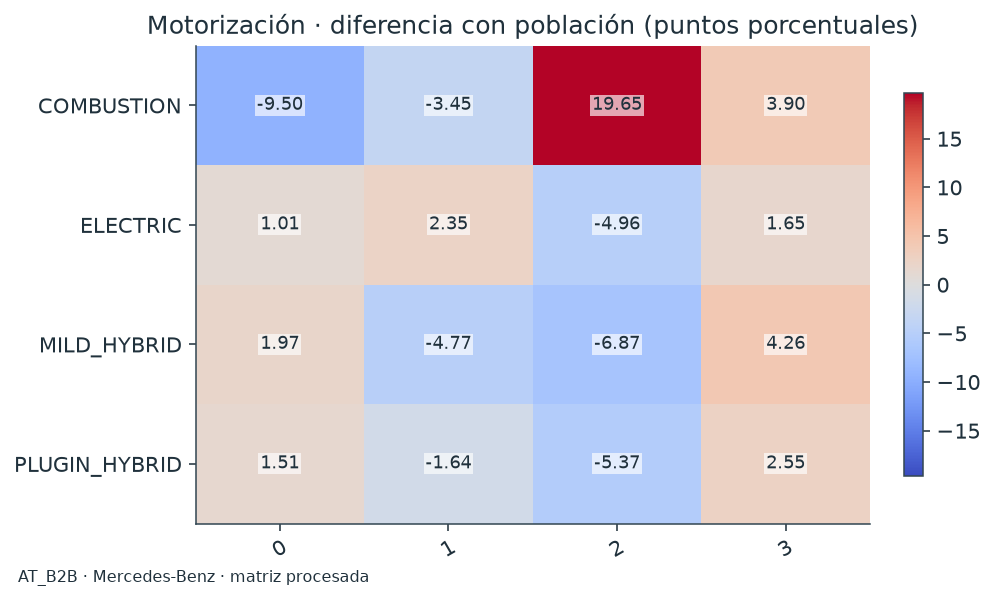

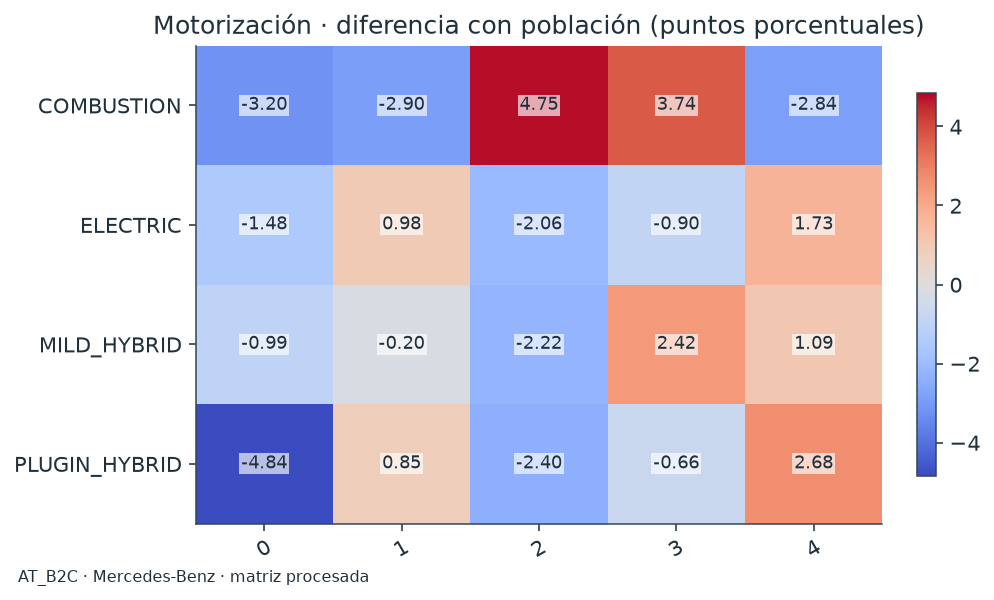

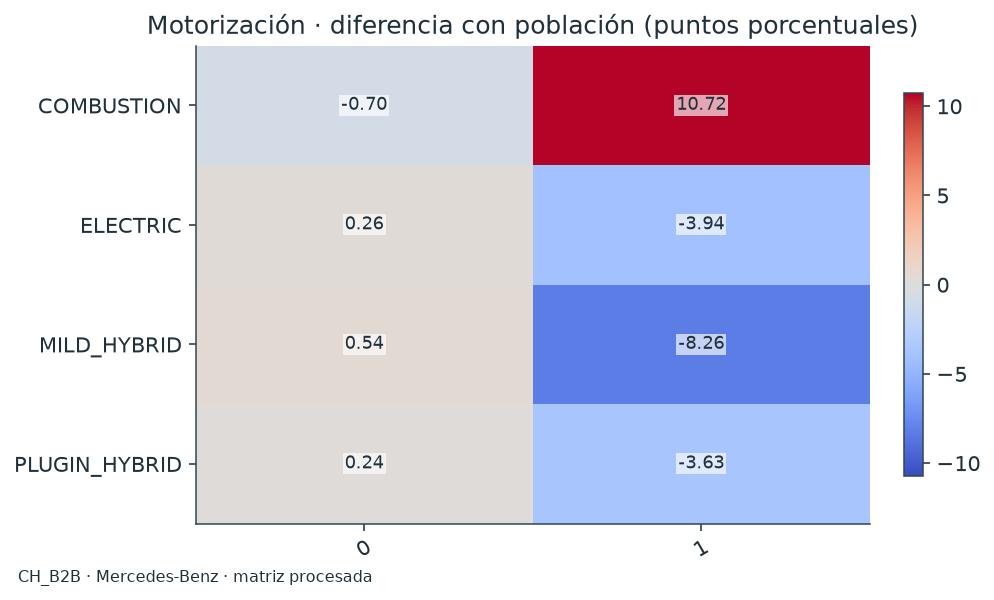

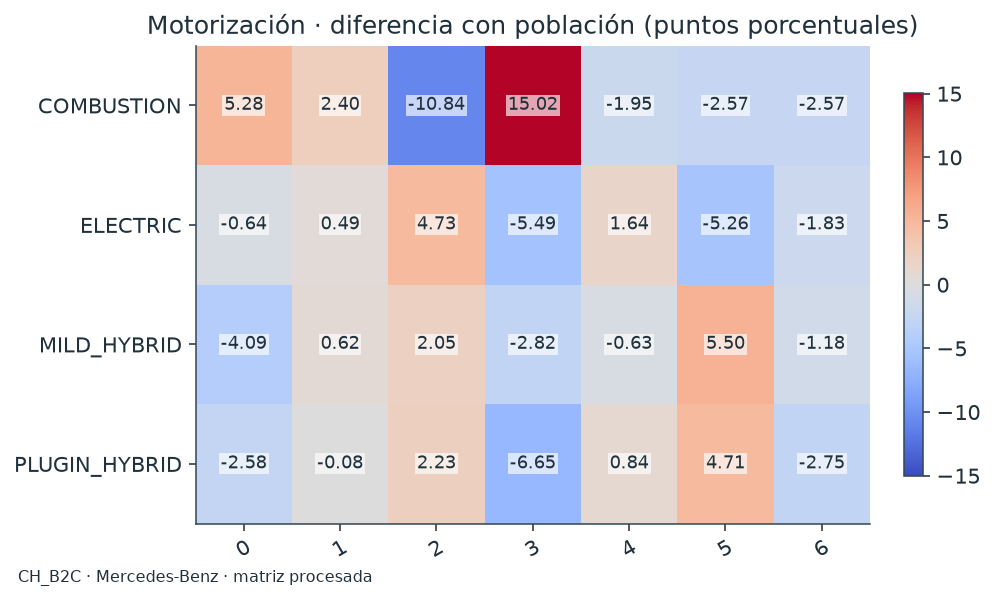

In [13]:
for segment, context in analyses.items():
    view = context["composition"].loc[lambda t:t["field"].eq("engine_concept")]
    matrix = view.pivot(index="category",columns="cluster",values="difference_pp")
    limit = max(1.,float(np.abs(matrix.to_numpy()).max()))
    plot_heatmap(matrix,"Motorización · diferencia con población (puntos porcentuales)",
        vmin=-limit,vmax=limit,cmap="coolwarm")
    show_figures(segment)


## Canales registrados para diseñar el piloto

Los consentimientos se describen después del clustering: no separan geométricamente los clientes. La tabla muestra disponibilidad registrada por canal y cluster. No mide respuesta ni implica que todos los candidatos del estudio puedan recibir una campaña; la audiencia final debe cruzarse con el estado de contacto vigente.


In [14]:
for segment, context in analyses.items():
    channels = context["composition"].loc[lambda t:
        t["field"].str.startswith("consent_") & t["category"].str.casefold().isin(["true","1"])]
    display_table(channels[["cluster","field","count","n_clients","share_all","unknown_fraction","difference_pp"]],
        segment+" · disponibilidad registrada de canales",max_rows=24)


AT_B2B · disponibilidad registrada de canales


,Cluster,Atributo,Clientes con atributo,Clientes,Proporción total,Desconocidos / total,Diferencia (pp)
157,0,consent_phone_communication_channel,1236,1240,0.9968,0.0,17.7980
159,1,consent_phone_communication_channel,188,219,0.8584,0.0,3.9653
161,2,consent_phone_communication_channel,480,533,0.9006,0.0,8.1768
163,3,consent_phone_communication_channel,161,530,0.3038,0.0,-51.5021
165,0,consent_epost_communication_channel,1239,1240,0.9992,0.0,0.4745
167,1,consent_epost_communication_channel,217,219,0.9909,0.0,-0.3581
169,2,consent_epost_communication_channel,530,533,0.9944,0.0,-0.0077
171,3,consent_epost_communication_channel,522,530,0.9849,0.0,-0.9543
173,0,consent_post_communication_channel,1235,1240,0.9960,0.0,15.1400
175,1,consent_post_communication_channel,195,219,0.8904,0.0,4.5843


AT_B2C · disponibilidad registrada de canales


,Cluster,Atributo,Clientes con atributo,Clientes,Proporción total,Desconocidos / total,Diferencia (pp)
271,0,consent_phone_communication_channel,7788,9067,0.8589,0.0,1.6156
273,1,consent_phone_communication_channel,1542,14679,0.1050,0.0,-73.7735
275,2,consent_phone_communication_channel,28402,29283,0.9699,0.0,12.7132
277,3,consent_phone_communication_channel,12193,13269,0.9189,0.0,7.6126
279,4,consent_phone_communication_channel,40632,41152,0.9874,0.0,14.4581
281,0,consent_epost_communication_channel,8769,9067,0.9671,0.0,-1.1871
283,1,consent_epost_communication_channel,12923,14679,0.8804,0.0,-9.8631
285,2,consent_epost_communication_channel,29237,29283,0.9984,0.0,1.9425
287,3,consent_epost_communication_channel,13160,13269,0.9918,0.0,1.2781
289,4,consent_epost_communication_channel,41105,41152,0.9989,0.0,1.9854


CH_B2B · disponibilidad registrada de canales


,Cluster,Atributo,Clientes con atributo,Clientes,Proporción total,Desconocidos / total,Diferencia (pp)
79,0,consent_phone_communication_channel,2116,2816,0.7514,0.0,-0.8833
81,1,consent_phone_communication_channel,164,183,0.8962,0.0,13.5921
83,0,consent_epost_communication_channel,2785,2816,0.9890,0.0,-0.0338
85,1,consent_epost_communication_channel,182,183,0.9945,0.0,0.5206
87,0,consent_post_communication_channel,2154,2816,0.7649,0.0,-0.9010
89,1,consent_post_communication_channel,167,183,0.9126,0.0,13.8644


CH_B2C · disponibilidad registrada de canales


,Cluster,Atributo,Clientes con atributo,Clientes,Proporción total,Desconocidos / total,Diferencia (pp)
393,0,consent_phone_communication_channel,43213,44993,0.9604,0.0,9.4308
395,1,consent_phone_communication_channel,46273,49070,0.9430,0.0,7.6869
397,2,consent_phone_communication_channel,34193,34801,0.9825,0.0,11.6399
399,3,consent_phone_communication_channel,9052,9465,0.9564,0.0,9.0235
401,4,consent_phone_communication_channel,1017,19586,0.0519,0.0,-81.4206
403,5,consent_phone_communication_channel,23217,23738,0.9781,0.0,11.1922
405,6,consent_phone_communication_channel,7495,8226,0.9111,0.0,4.5005
407,0,consent_epost_communication_channel,44865,44993,0.9972,0.0,1.1859
409,1,consent_epost_communication_channel,48801,49070,0.9945,0.0,0.9222
411,2,consent_epost_communication_channel,34778,34801,0.9993,0.0,1.4043


## Perfiles y heterogeneidad

Partimos de los tamaños y fronteras de 03. El contraste (media del grupo−media global)/desviación global solo describe el perfil; no cambia X. Se acompañan medias de medianas. Las coordenadas procesadas no recuperan euros, años o velocidades originales.


In [15]:
for segment, context in analyses.items():
    profiles,distinctive,hypotheses = campaign_hypotheses(context["data"],context["labels"],
        FEATURE_DESCRIPTIONS,min_contrast=MIN_PROFILE_CONTRAST)
    context.update(profiles=profiles,distinctive=distinctive,hypotheses=hypotheses)
    display_table(distinctive[["cluster","feature","mean","median","standardized_mean_difference"]],
        segment+" · coordenadas distintivas",max_rows=24)
    keep_table(segment,"perfiles completos",profiles)


AT_B2B · coordenadas distintivas


,Cluster,Feature,mean,median,standardized_mean_difference
0,0,marketing_receptivity_score,0.4824,0.4941,0.4824
1,0,population,-0.4474,-0.5403,-0.4474
2,0,fuel_consumption_average,-0.4213,-0.2488,-0.4213
3,1,is_current_vehicle,2.3972,2.7062,2.3972
4,1,has_telemetry_active,2.1499,2.7635,2.1499
5,1,operating_hours_total,1.4905,0.6324,1.4905
6,2,speed_median,-1.4621,-1.3334,-1.4621
7,2,fuel_consumption_average,1.3480,1.3547,1.3480
8,2,months_as_mb_customer,-0.3365,-0.4928,-0.3365
9,3,marketing_receptivity_score,-1.3258,-2.3937,-1.3258


AT_B2C · coordenadas distintivas


,Cluster,Feature,mean,median,standardized_mean_difference
0,0,currently_connected_vehicles,2.9679,2.9651,2.9679
1,0,months_as_mb_customer,0.9029,0.8937,0.9029
2,0,is_current_vehicle,-0.5406,-1.1851,-0.5406
3,1,marketing_receptivity_score,-2.2083,-2.3925,-2.2083
4,1,has_telemetry_active,-0.4411,-0.8895,-0.4411
5,1,currently_connected_vehicles,-0.2635,-0.3802,-0.2635
6,2,is_current_vehicle,-1.1142,-1.1851,-1.1142
7,2,marketing_receptivity_score,0.3860,0.4632,0.3860
8,2,months_as_mb_customer,0.3856,0.3689,0.3856
9,3,population,2.1403,1.8961,2.1403


CH_B2B · coordenadas distintivas


,Cluster,Feature,mean,median,standardized_mean_difference
0,0,is_current_vehicle,-0.1876,-0.2989,-0.1876
1,0,has_telemetry_active,-0.1749,-0.3029,-0.1749
2,0,workshop_frequency_yearly,-0.1680,-0.1850,-0.1680
3,1,is_current_vehicle,2.8873,3.3453,2.8873
4,1,has_telemetry_active,2.6910,3.3016,2.6910
5,1,workshop_frequency_yearly,2.5858,1.9601,2.5858


CH_B2C · coordenadas distintivas


,Cluster,Feature,mean,median,standardized_mean_difference
0,0,is_current_vehicle,-1.2544,-1.2650,-1.2544
1,0,has_telemetry_active,-0.6630,-0.8081,-0.6630
2,0,workshop_frequency_yearly,-0.5212,-0.8145,-0.5212
3,1,has_telemetry_active,-0.8074,-0.8081,-0.8074
4,1,is_current_vehicle,0.7839,0.7905,0.7839
5,1,months_as_mb_customer,-0.2862,-0.3205,-0.2862
6,2,has_telemetry_active,1.2204,1.2374,1.2204
7,2,speed_median,0.5866,0.3475,0.5866
8,2,trip_distance_median,0.4518,0.2790,0.4518
9,3,operating_hours_total,3.1512,2.5634,3.1512


## Qué distingue a cada grupo

La figura compara signos y magnitudes sobre la misma población. El área geográfica es contexto, no renta personal. Una variable de uso o un score puede depender de codificación o disponibilidad; las denominaciones siguientes describen contrastes, no identidades permanentes de clientes.


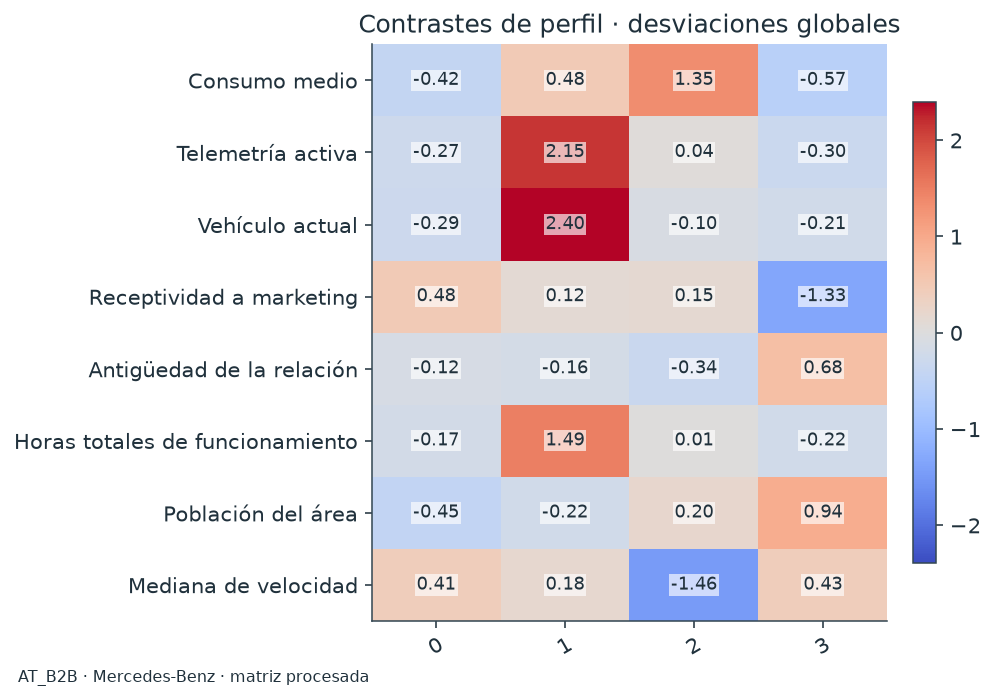

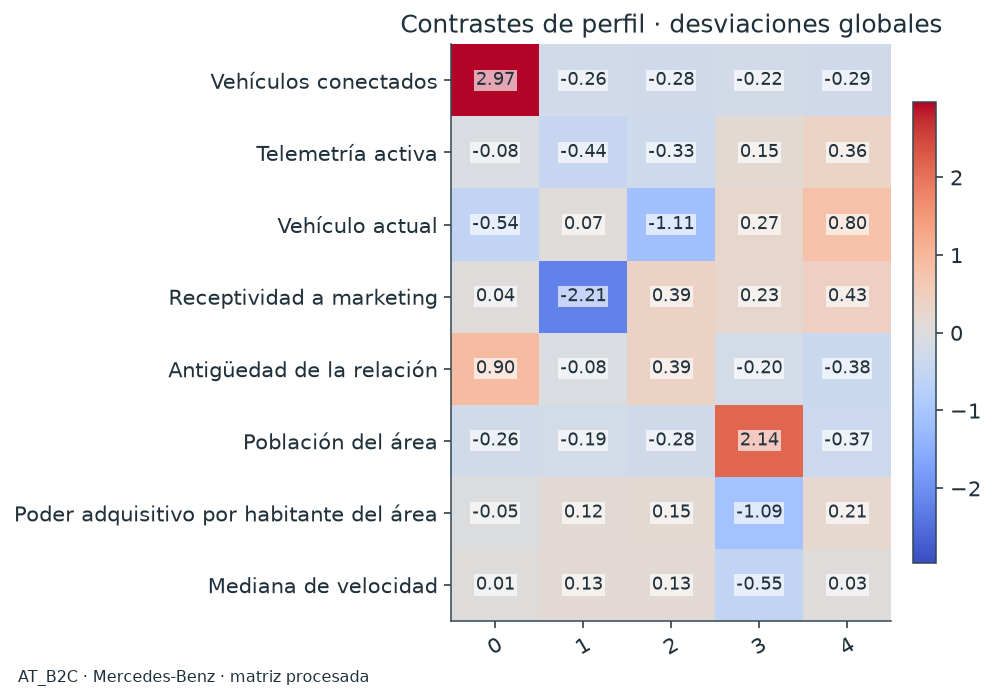

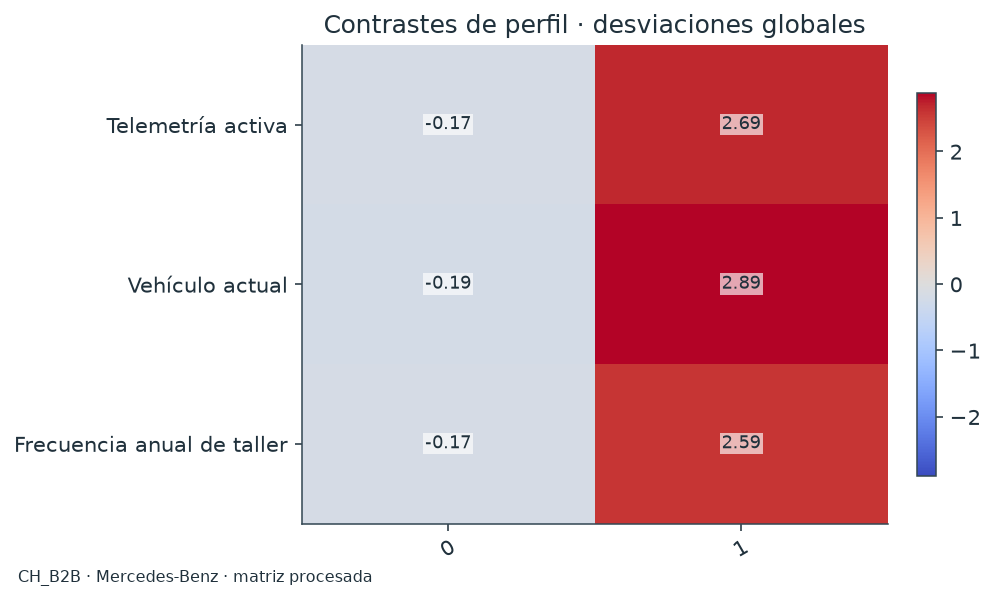

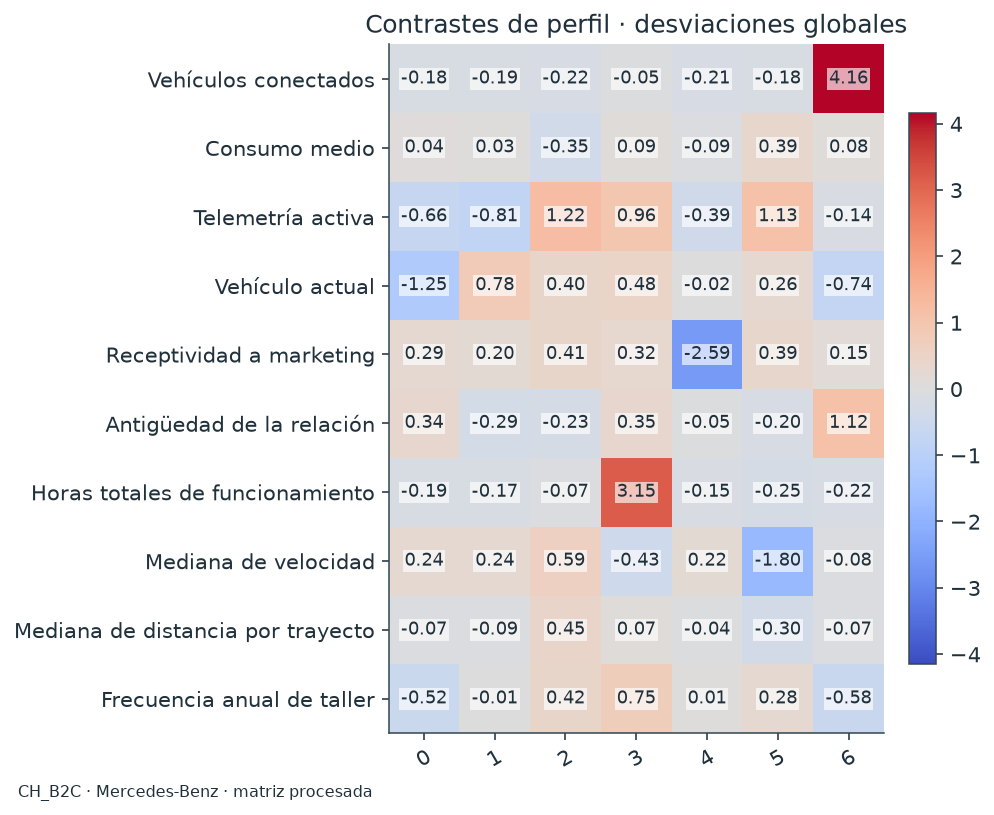

In [16]:
for segment, context in analyses.items():
    names = context["distinctive"]["feature"].drop_duplicates().head(12)
    matrix = context["profiles"].loc[lambda value:value["feature"].isin(names)].pivot(
        index="feature",columns="cluster",values="standardized_mean_difference")
    matrix.index = [FEATURE_DESCRIPTIONS.get(name,name) for name in matrix.index]
    limit = max(1.,float(np.abs(matrix.to_numpy()).max()))
    plot_heatmap(matrix,"Contrastes de perfil · desviaciones globales",vmin=-limit,vmax=limit,cmap="coolwarm")
    show_figures(segment)


## Hipótesis de segmentación para campañas

La tabla une evidencia, acción candidata y resultado a medir. El eje descriptivo utiliza la familia con mayor contraste absoluto; ≥0.35 σ es un umbral exploratorio declarado. Una hipótesis de servicio, conectividad o canal territorial necesita un piloto: no se atribuye una mejora de conversión a estas diferencias.


In [17]:
for segment, context in analyses.items():
    cards = context["hypotheses"].merge(context["business_cards"],on="cluster",validate="one_to_one")
    context["hypotheses"] = cards
    display_table(cards[["cluster","fraction","descriptive_axis","observed_evidence","candidate_campaign","pilot_outcome"]],
        segment+" · argumento comercial a contrastar",max_rows=24)
    display_table(cards[["cluster","business_evidence"]],segment+" · lectura comercial del cruce",max_rows=24)
    context["entry"]["marketing_hypotheses"] = cards.to_dict(orient="records")
    context["entry"]["campaign_eligibility"] = {str(int(row.cluster)): bool(row.contrast_strength>=MIN_PROFILE_CONTRAST)
        for row in cards.itertuples()}
    context["entry"]["steps"] = sorted(set(context["entry"]["steps"]+["04"]))
    keep_table(segment,"hipótesis de campañas",cards)


AT_B2B · argumento comercial a contrastar


,Cluster,Proporción,Eje descriptivo,Contraste de comportamiento,Hipótesis de campaña,Resultado del piloto
0,0,0.4917,Interacción con marketing,Receptividad a marketing +0.48 σ; Población del área -0.45 σ; Consumo medio -0.42 σ,Contrastar formato o frecuencia de contacto mediante un piloto,Respuesta incremental; verificar cómo se construyó el score
1,1,0.0868,Ciclo de relación y vehículo,Vehículo actual +2.40 σ; Telemetría activa +2.15 σ; Horas totales de funcionamiento +1.49 σ,Probar contenidos de mantenimiento o renovación ajustados al ciclo de relación,Citas o renovaciones incrementales frente a control
2,2,0.2113,Uso observado,Mediana de velocidad -1.46 σ; Consumo medio +1.35 σ; Antigüedad de la relación -0.34 σ,Contrastar contenidos de servicio según patrones de uso verificados,Citas o interacción incremental; validar la medición del uso
3,3,0.2102,Interacción con marketing,Receptividad a marketing -1.33 σ; Población del área +0.94 σ; Antigüedad de la relación +0.68 σ,Contrastar formato o frecuencia de contacto mediante un piloto,Respuesta incremental; verificar cómo se construyó el score


AT_B2B · lectura comercial del cruce


,Cluster,Composición de negocio observada
0,0,"Clase de vehículo: V-Class / Vito, 498/1240 (40.2%; población 27.6%; desconocido 1.3%); Estado de financiación/leasing: active_FL_and_CASH, 478/1240 (38.5%; población 25.0%; desconocido 0.0%); Motorización: COMBUSTION, 276/1240 (22.3%; población 31.8%; desconocido 55.5%)"
1,1,"Clase de vehículo: V-Class / Vito, 81/219 (37.0%; población 27.6%; desconocido 0.5%); Estado de financiación/leasing: never_active, 137/219 (62.6%; población 30.5%; desconocido 0.0%); Motorización: COMBUSTION, 62/219 (28.3%; población 31.8%; desconocido 58.0%)"
2,2,"Clase de vehículo: Sprinter, 519/533 (97.4%; población 24.1%; desconocido 0.0%); Estado de financiación/leasing: never_active, 196/533 (36.8%; población 30.5%; desconocido 0.0%); Motorización: COMBUSTION, 274/533 (51.4%; población 31.8%; desconocido 48.0%)"
3,3,"Clase de vehículo: V-Class / Vito, 112/530 (21.1%; población 27.6%; desconocido 1.9%); Estado de financiación/leasing: was_active, 247/530 (46.6%; población 24.8%; desconocido 0.0%); Motorización: COMBUSTION, 189/530 (35.7%; población 31.8%; desconocido 38.1%)"


AT_B2C · argumento comercial a contrastar


...

,Cluster,Composición de negocio observada
0,0,"Clase de vehículo: Sprinter, 675/2816 (24.0%; población 25.1%; desconocido 2.8%); Estado de financiación/leasing: never_active, 1131/2816 (40.2%; población 41.3%; desconocido 0.0%); Motorización: COMBUSTION, 725/2816 (25.7%; población 26.4%; desconocido 51.4%)"
1,1,"Clase de vehículo: Sprinter, 78/183 (42.6%; población 25.1%; desconocido 0.0%); Estado de financiación/leasing: never_active, 108/183 (59.0%; población 41.3%; desconocido 0.0%); Motorización: COMBUSTION, 68/183 (37.2%; población 26.4%; desconocido 56.8%)"


CH_B2C · argumento comercial a contrastar


,Cluster,Proporción,Eje descriptivo,Contraste de comportamiento,Hipótesis de campaña,Resultado del piloto
0,0,0.2370,Ciclo de relación y vehículo,Vehículo actual -1.25 σ; Telemetría activa -0.66 σ; Frecuencia anual de taller -0.52 σ,Probar contenidos de mantenimiento o renovación ajustados al ciclo de relación,Citas o renovaciones incrementales frente a control
1,1,0.2584,Conectividad,Telemetría activa -0.81 σ; Vehículo actual +0.78 σ; Antigüedad de la relación -0.29 σ,Contrastar onboarding o contenidos sobre servicios conectados,Activación o uso incremental del servicio frente a control
2,2,0.1833,Conectividad,Telemetría activa +1.22 σ; Mediana de velocidad +0.59 σ; Mediana de distancia por trayecto +0.45 σ,Contrastar onboarding o contenidos sobre servicios conectados,Activación o uso incremental del servicio frente a control
3,3,0.0498,Uso observado,Horas totales de funcionamiento +3.15 σ; Telemetría activa +0.96 σ; Frecuencia anual de taller +0.75 σ,Contrastar contenidos de servicio según patrones de uso verificados,Citas o interacción incremental; validar la medición del uso
4,4,0.1031,Interacción con marketing,Receptividad a marketing -2.59 σ; Telemetría activa -0.39 σ; Mediana de velocidad +0.22 σ,Contrastar formato o frecuencia de contacto mediante un piloto,Respuesta incremental; verificar cómo se construyó el score
5,5,0.1250,Uso observado,Mediana de velocidad -1.80 σ; Telemetría activa +1.13 σ; Consumo medio +0.39 σ,Contrastar contenidos de servicio según patrones de uso verificados,Citas o interacción incremental; validar la medición del uso
6,6,0.0433,Conectividad,Vehículos conectados +4.16 σ; Antigüedad de la relación +1.12 σ; Vehículo actual -0.74 σ,Contrastar onboarding o contenidos sobre servicios conectados,Activación o uso incremental del servicio frente a control


CH_B2C · lectura comercial del cruce


,Cluster,Composición de negocio observada
0,0,"Clase de vehículo: C-Class, 6706/44993 (14.9%; población 12.0%; desconocido 0.8%); Estado de financiación/leasing: never_active, 21458/44993 (47.7%; población 54.2%; desconocido 0.0%); Motorización: COMBUSTION, 21197/44993 (47.1%; población 41.8%; desconocido 33.3%)"
1,1,"Clase de vehículo: GLC-Class, 8346/49070 (17.0%; población 15.5%; desconocido 2.5%); Estado de financiación/leasing: never_active, 31775/49070 (64.8%; población 54.2%; desconocido 0.0%); Motorización: COMBUSTION, 21707/49070 (44.2%; población 41.8%; desconocido 27.9%)"
2,2,"Clase de vehículo: GLC-Class, 5730/34801 (16.5%; población 15.5%; desconocido 0.1%); Estado de financiación/leasing: never_active, 19548/34801 (56.2%; población 54.2%; desconocido 0.0%); Motorización: COMBUSTION, 10788/34801 (31.0%; población 41.8%; desconocido 33.1%)"
3,3,"Clase de vehículo: V-Class / Vito, 1359/9465 (14.4%; población 8.0%; desconocido 0.0%); Estado de financiación/leasing: never_active, 5430/9465 (57.4%; población 54.2%; desconocido 0.0%); Motorización: COMBUSTION, 5381/9465 (56.9%; población 41.8%; desconocido 31.2%)"
4,4,"Clase de vehículo: GLC-Class, 3088/19586 (15.8%; población 15.5%; desconocido 1.3%); Estado de financiación/leasing: never_active, 11123/19586 (56.8%; población 54.2%; desconocido 0.0%); Motorización: COMBUSTION, 7813/19586 (39.9%; población 41.8%; desconocido 31.4%)"
5,5,"Clase de vehículo: GLC-Class, 4786/23738 (20.2%; población 15.5%; desconocido 0.0%); Estado de financiación/leasing: never_active, 12428/23738 (52.4%; población 54.2%; desconocido 0.0%); Motorización: COMBUSTION, 9322/23738 (39.3%; población 41.8%; desconocido 28.9%)"
6,6,"Clase de vehículo: C-Class, 1064/8226 (12.9%; población 12.0%; desconocido 1.1%); Estado de financiación/leasing: was_active, 4201/8226 (51.1%; población 10.9%; desconocido 0.0%); Motorización: COMBUSTION, 3230/8226 (39.3%; población 41.8%; desconocido 39.6%)"


## Cómo validar la hipótesis

Antes de seleccionar destinatarios: verificar el vínculo de la clave técnica con el cliente, el significado de las transformaciones y los criterios de contacto de la campaña. La evaluación de respuesta necesita resultados posteriores que no aparecen en estos CSV. El score de receptividad no puede sustituir una medición incremental.


In [18]:
design = pd.DataFrame([
    ("Pregunta","¿Cambiar contenido o canal según el segmento mejora el resultado frente a la regla actual?"),
    ("Comparación","Asignar aleatoriamente tratamiento y control dentro de cada segmento; fijar unidad cliente y evitar contactos duplicados."),
    ("Resultado primario","Definir antes del piloto conversión, cita o activación, ventana de observación y denominador de clientes asignados."),
    ("Análisis","Medir diferencia de tasas y su incertidumbre; planificar tamaño y multiplicidad antes de explorar segmentos."),
    ("Continuidad","05 comprueba dependencia del algoritmo; 06 muestra qué estructura concentra la varianza; 07 delimita candidatos consistentes."),
],columns=["Decisión","Diseño propuesto"])
display_table(design,"Diseño de validación comercial")
for segment, context in analyses.items():
    cards = context["hypotheses"]
    context["findings"] = [f"C{int(row.cluster)} ({row.fraction:.1%}): {row.observed_evidence}. {row.business_evidence}. Hipótesis: {row.candidate_campaign}."
        for row in cards.itertuples()]
    context["findings"] += ["Estos contrastes no predicen quién responderá. La prioridad de piloto queda pendiente de acuerdo entre modelos y robustez."]
    display(ReportPanel(segment+" · lectura comercial",{},context["findings"],"Hipótesis contrastables; sin efecto comercial estimado"))


Diseño de validación comercial


,Decisión,Diseño propuesto
0,Pregunta,¿Cambiar contenido o canal según el segmento mejora el resultado frente a la regla actual?
1,Comparación,Asignar aleatoriamente tratamiento y control dentro de cada segmento; fijar unidad cliente y evitar contactos duplicados.
2,Resultado primario,"Definir antes del piloto conversión, cita o activación, ventana de observación y denominador de clientes asignados."
3,Análisis,Medir diferencia de tasas y su incertidumbre; planificar tamaño y multiplicidad antes de explorar segmentos.
4,Continuidad,05 comprueba dependencia del algoritmo; 06 muestra qué estructura concentra la varianza; 07 delimita candidatos consistentes.


# AT_B2B · lectura comercial

Hipótesis contrastables; sin efecto comercial estimado

| Indicador | Resultado |
| --- | --- |

- C0 (49.2%): Receptividad a marketing +0.48 σ; Población del área -0.45 σ; Consumo medio -0.42 σ. Clase de vehículo: V-Class / Vito, 498/1240 (40.2%; población 27.6%; desconocido 1.3%); Estado de financiación/leasing: active_FL_and_CASH, 478/1240 (38.5%; población 25.0%; desconocido 0.0%); Motorización: COMBUSTION, 276/1240 (22.3%; población 31.8%; desconocido 55.5%). Hipótesis: Contrastar formato o frecuencia de contacto mediante un piloto.
- C1 (8.7%): Vehículo actual +2.40 σ; Telemetría activa +2.15 σ; Horas totales de funcionamiento +1.49 σ. Clase de vehículo: V-Class / Vito, 81/219 (37.0%; población 27.6%; desconocido 0.5%); Estado de financiación/leasing: never_active, 137/219 (62.6%; población 30.5%; desconocido 0.0%); Motorización: COMBUSTION, 62/219 (28.3%; población 31.8%; desconocido 58.0%). Hipótesis: Probar contenidos de mantenimiento o renovación ajustados al ciclo de relación.
- C2 (21.1%): Mediana de velocidad -1.46 σ; Consumo medio +1.35 σ; Antigüedad de la relación -0.34 σ. Clase de vehículo: Sprinter, 519/533 (97.4%; población 24.1%; desconocido 0.0%); Estado de financiación/leasing: never_active, 196/533 (36.8%; población 30.5%; desconocido 0.0%); Motorización: COMBUSTION, 274/533 (51.4%; población 31.8%; desconocido 48.0%). Hipótesis: Contrastar contenidos de servicio según patrones de uso verificados.
- C3 (21.0%): Receptividad a marketing -1.33 σ; Población del área +0.94 σ; Antigüedad de la relación +0.68 σ. Clase de vehículo: V-Class / Vito, 112/530 (21.1%; población 27.6%; desconocido 1.9%); Estado de financiación/leasing: was_active, 247/530 (46.6%; población 24.8%; desconocido 0.0%); Motorización: COMBUSTION, 189/530 (35.7%; población 31.8%; desconocido 38.1%). Hipótesis: Contrastar formato o frecuencia de contacto mediante un piloto.
- Estos contrastes no predicen quién responderá. La prioridad de piloto queda pendiente de acuerdo entre modelos y robustez.

# AT_B2C · lectura comercial

Hipótesis contrastables; sin efecto comercial estimado

| Indicador | Resultado |
| --- | --- |

- C0 (8.4%): Vehículos conectados +2.97 σ; Antigüedad de la relación +0.90 σ; Vehículo actual -0.54 σ. Clase de vehículo: V-Class / Vito, 1529/9067 (16.9%; población 10.1%; desconocido 2.3%); Estado de financiación/leasing: active_FL_and_CASH, 5848/9067 (64.5%; población 13.4%; desconocido 0.0%); Motorización: COMBUSTION, 3137/9067 (34.6%; población 37.8%; desconocido 43.6%). Hipótesis: Contrastar onboarding o contenidos sobre servicios conectados.
- C1 (13.7%): Receptividad a marketing -2.21 σ; Telemetría activa -0.44 σ; Vehículos conectados -0.26 σ. Clase de vehículo: GLC-Class, 2108/14679 (14.4%; población 13.4%; desconocido 1.4%); Estado de financiación/leasing: never_active, 10421/14679 (71.0%; población 66.7%; desconocido 0.0%); Motorización: COMBUSTION, 5123/14679 (34.9%; población 37.8%; desconocido 34.3%). Hipótesis: Contrastar formato o frecuencia de contacto mediante un piloto.
- C2 (27.3%): Vehículo actual -1.11 σ; Receptividad a marketing +0.39 σ; Antigüedad de la relación +0.39 σ. Clase de vehículo: C-Class, 3859/29283 (13.2%; población 11.0%; desconocido 0.6%); Estado de financiación/leasing: never_active, 17247/29283 (58.9%; población 66.7%; desconocido 0.0%); Motorización: COMBUSTION, 12460/29283 (42.6%; población 37.8%; desconocido 35.0%). Hipótesis: Probar contenidos de mantenimiento o renovación ajustados al ciclo de relación.
- C3 (12.3%): Población del área +2.14 σ; Poder adquisitivo por habitante del área -1.09 σ; Mediana de velocidad -0.55 σ. Clase de vehículo: C-Class, 1591/13269 (12.0%; población 11.0%; desconocido 0.9%); Estado de financiación/leasing: never_active, 9446/13269 (71.2%; población 66.7%; desconocido 0.0%); Motorización: COMBUSTION, 5512/13269 (41.5%; población 37.8%; desconocido 28.5%). Hipótesis: Contrastar adaptación territorial del canal y cobertura.
- C4 (38.3%): Vehículo actual +0.80 σ; Receptividad a marketing +0.43 σ; Antigüedad de la relación -0.38 σ. Clase de vehículo: GLC-Class, 6134/41152 (14.9%; población 13.4%; desconocido 1.4%); Estado de financiación/leasing: never_active, 32134/41152 (78.1%; población 66.7%; desconocido 0.0%); Motorización: COMBUSTION, 14386/41152 (35.0%; población 37.8%; desconocido 30.4%). Hipótesis: Probar contenidos de mantenimiento o renovación ajustados al ciclo de relación.
- Estos contrastes no predicen quién responderá. La prioridad de piloto queda pendiente de acuerdo entre modelos y robustez.

# CH_B2B · lectura comercial

Hipótesis contrastables; sin efecto comercial estimado

| Indicador | Resultado |
| --- | --- |

- C0 (93.9%): Vehículo actual -0.19 σ; Telemetría activa -0.17 σ; Frecuencia anual de taller -0.17 σ. Clase de vehículo: Sprinter, 675/2816 (24.0%; población 25.1%; desconocido 2.8%); Estado de financiación/leasing: never_active, 1131/2816 (40.2%; población 41.3%; desconocido 0.0%); Motorización: COMBUSTION, 725/2816 (25.7%; población 26.4%; desconocido 51.4%). Hipótesis: No hay contraste suficiente para diferenciar una campaña.
- C1 (6.1%): Vehículo actual +2.89 σ; Telemetría activa +2.69 σ; Frecuencia anual de taller +2.59 σ. Clase de vehículo: Sprinter, 78/183 (42.6%; población 25.1%; desconocido 0.0%); Estado de financiación/leasing: never_active, 108/183 (59.0%; población 41.3%; desconocido 0.0%); Motorización: COMBUSTION, 68/183 (37.2%; población 26.4%; desconocido 56.8%). Hipótesis: Probar contenidos de mantenimiento o renovación ajustados al ciclo de relación.
- Estos contrastes no predicen quién responderá. La prioridad de piloto queda pendiente de acuerdo entre modelos y robustez.

# CH_B2C · lectura comercial

Hipótesis contrastables; sin efecto comercial estimado

| Indicador | Resultado |
| --- | --- |

- C0 (23.7%): Vehículo actual -1.25 σ; Telemetría activa -0.66 σ; Frecuencia anual de taller -0.52 σ. Clase de vehículo: C-Class, 6706/44993 (14.9%; población 12.0%; desconocido 0.8%); Estado de financiación/leasing: never_active, 21458/44993 (47.7%; población 54.2%; desconocido 0.0%); Motorización: COMBUSTION, 21197/44993 (47.1%; población 41.8%; desconocido 33.3%). Hipótesis: Probar contenidos de mantenimiento o renovación ajustados al ciclo de relación.
- C1 (25.8%): Telemetría activa -0.81 σ; Vehículo actual +0.78 σ; Antigüedad de la relación -0.29 σ. Clase de vehículo: GLC-Class, 8346/49070 (17.0%; población 15.5%; desconocido 2.5%); Estado de financiación/leasing: never_active, 31775/49070 (64.8%; población 54.2%; desconocido 0.0%); Motorización: COMBUSTION, 21707/49070 (44.2%; población 41.8%; desconocido 27.9%). Hipótesis: Contrastar onboarding o contenidos sobre servicios conectados.
- C2 (18.3%): Telemetría activa +1.22 σ; Mediana de velocidad +0.59 σ; Mediana de distancia por trayecto +0.45 σ. Clase de vehículo: GLC-Class, 5730/34801 (16.5%; población 15.5%; desconocido 0.1%); Estado de financiación/leasing: never_active, 19548/34801 (56.2%; población 54.2%; desconocido 0.0%); Motorización: COMBUSTION, 10788/34801 (31.0%; población 41.8%; desconocido 33.1%). Hipótesis: Contrastar onboarding o contenidos sobre servicios conectados.
- C3 (5.0%): Horas totales de funcionamiento +3.15 σ; Telemetría activa +0.96 σ; Frecuencia anual de taller +0.75 σ. Clase de vehículo: V-Class / Vito, 1359/9465 (14.4%; población 8.0%; desconocido 0.0%); Estado de financiación/leasing: never_active, 5430/9465 (57.4%; población 54.2%; desconocido 0.0%); Motorización: COMBUSTION, 5381/9465 (56.9%; población 41.8%; desconocido 31.2%). Hipótesis: Contrastar contenidos de servicio según patrones de uso verificados.
- C4 (10.3%): Receptividad a marketing -2.59 σ; Telemetría activa -0.39 σ; Mediana de velocidad +0.22 σ. Clase de vehículo: GLC-Class, 3088/19586 (15.8%; población 15.5%; desconocido 1.3%); Estado de financiación/leasing: never_active, 11123/19586 (56.8%; población 54.2%; desconocido 0.0%); Motorización: COMBUSTION, 7813/19586 (39.9%; población 41.8%; desconocido 31.4%). Hipótesis: Contrastar formato o frecuencia de contacto mediante un piloto.
- C5 (12.5%): Mediana de velocidad -1.80 σ; Telemetría activa +1.13 σ; Consumo medio +0.39 σ. Clase de vehículo: GLC-Class, 4786/23738 (20.2%; población 15.5%; desconocido 0.0%); Estado de financiación/leasing: never_active, 12428/23738 (52.4%; población 54.2%; desconocido 0.0%); Motorización: COMBUSTION, 9322/23738 (39.3%; población 41.8%; desconocido 28.9%). Hipótesis: Contrastar contenidos de servicio según patrones de uso verificados.
- C6 (4.3%): Vehículos conectados +4.16 σ; Antigüedad de la relación +1.12 σ; Vehículo actual -0.74 σ. Clase de vehículo: C-Class, 1064/8226 (12.9%; población 12.0%; desconocido 1.1%); Estado de financiación/leasing: was_active, 4201/8226 (51.1%; población 10.9%; desconocido 0.0%); Motorización: COMBUSTION, 3230/8226 (39.3%; población 41.8%; desconocido 39.6%). Hipótesis: Contrastar onboarding o contenidos sobre servicios conectados.
- Estos contrastes no predicen quién responderá. La prioridad de piloto queda pendiente de acuerdo entre modelos y robustez.

## Alcance y siguiente decisión

Las denominaciones propuestas son descriptivas. Evitar inferir renta individual del área, insatisfacción de visitas en garantía o preferencias del score sin conocer su construcción. La comparación siguiente probará cuánto cambia la lista de destinatarios al cambiar de algoritmo.


In [19]:
# El paquete conserva los resultados previos; cada cuaderno añade solo su aportación.
save_study(study, REFERENCE_FILE)
RUN_REPORT = dict(step="04", source="real", versions=VERSIONS,
    segments=[dict(segment_id=segment, clients=context["data"].n_samples,
                   features=context["data"].n_features, k=int(context["model"].n_clusters),
                   scaling_policy=context["representation"]["policy"])
              for segment, context in analyses.items()],
    findings={segment:context["findings"] for segment,context in analyses.items()},
    elapsed_seconds=round(perf_counter()-STARTED,3))
print("Resultados actualizados en " + REFERENCE_FILE + ". Para continuar en otra sesión, conservar este paquete junto a los CSV.")


Resultados actualizados en segmentacion_ml.zip. Para continuar en otra sesión, conservar este paquete junto a los CSV.
